# Consumer Financial Complaints Analysis
### INFO 4360 – Complex Data Analytics

**Team Members:** Rebecca Quaye and Ketty Odero  
**Project:** Consumer Complaint Classification Using Natural Language Processing (NLP)  
**Analysis Path:** Path A – Predictive Classification



## Project Overview

This project explores whether consumer complaint narratives can be used to predict the financial product category associated with a complaint.

We analyze a sample of 5,000 complaints from the Consumer Financial Protection Bureau (CFPB), covering 11 financial product categories between August 2025 and July 2026.

## Research Question

**Can consumer complaint narratives accurately predict the financial product category associated with a complaint?**

## Analysis Approach

Our analysis includes:

1. **Exploratory Data Analysis (EDA):** Examining product distributions, missing values, narrative lengths, and duplicate complaints.
2. **Text Preprocessing:** Cleaning complaint narratives and preparing text for analysis.
3. **Text Mining:** Exploring word frequencies, bigrams, TF-IDF, and product-specific vocabulary.
4. **Sentiment Analysis:** Comparing baseline VADER sentiment scores with an experimental domain-adjusted approach.
5. **Predictive Modeling (Planned):** Using TF-IDF with Logistic Regression, Naive Bayes, and Linear SVM to classify complaints.
6. **LLM Comparison (Planned):** Exploring Claude API classification and comparing its results with traditional machine learning models.

## Project Goal

Our goal is to understand patterns in consumer complaint narratives and investigate whether NLP can help organizations automatically categorize incoming complaints.


**Note:** The exploratory and text analyses are part of our Phase 2 development. Predictive modeling and LLM comparisons are planned for Phase 3.

## 0. Setup
### 0.1 Imports

In [1]:
# Show charts inside the notebook on the first run
%matplotlib inline

# Make the src/ folder importable
import sys
sys.path.append("..")   # also look one folder up for src/, in case the notebook runs from Notebook/

# Data handling
import os
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Text processing for the raw word counts in sections 2.2 and 2.3 (NLTK)
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download(["stopwords", "wordnet"], quiet=True)   # word lists needed by the cleaning step (skipped if already installed)

# Project helper functions (src/data_utils.py, src/preprocessing.py, src/text_analysis.py)
from src.data_utils import load_complaints, missing_values, duplicate_narratives, TEXT_COL, SHORT_NAMES
from src.preprocessing import (clean_text, drop_duplicate_narratives, top_terms,
                               distinctive_terms, product_word_matrix, STOPWORDS)
from src.text_analysis import (sentiment_scores, sentiment_label, positive_word_contributions,
                               FINANCE_WORDS)

# Claude API (used from section 3.4 on)
from concurrent.futures import ThreadPoolExecutor   # send several requests at the same time
import anthropic                                    # official Claude API client
from dotenv import load_dotenv                      # reads the API key from .env (never printed)

# Modeling (section 3)
import spacy                                        # word vectors for model 3 (class 6, Exercise 3)
from sklearn.base import clone                      # copy a model's settings without its fitted values
from sklearn.dummy import DummyClassifier           # majority-class baseline
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline               # TF-IDF + classifier as one model
from sklearn.preprocessing import normalize         # unit-length vectors for cosine similarity
from sklearn.svm import LinearSVC

# Notebook themes: one consistent chart style for every figure
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95,
              rc={"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12})
MAIN = sns.color_palette("deep")[0]      # one colour for every single-series chart
ACCENT = sns.color_palette("deep")[3]    # used only to highlight a key value
pd.set_option("display.max_colwidth", 200)   # show up to 200 characters of text in tables

### 0.2 Load the data

In [2]:
# Load the complaint sample. load_complaints reads the CSV, parses the dates and adds
# three helper columns: month, product_short (short product names) and word_count
DATA_PATH = "../Data/cfpb_complaints_sample_2025-08_to_2026-07.csv"
df = load_complaints(DATA_PATH)

## 1. Data exploration

### 1.1 Size and structure

A quick look at how many complaints we have, the period they cover, and the columns we will use.
Note: the 19 columns include 3 helper columns created by `load_complaints` (`month`, `product_short`, `word_count`).

In [3]:
# Preview the first two rows with every column, to see what each field looks like
df.head(2)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID,month,product_short,word_count
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a pattern of payment re-aging, unapplied funds, and fabricated fees on my post-discharge mortgage account. Agents repeatedly invoked bankruptcy discla...",Company has responded to the consumer and the CFPB and chooses not to provide a public response,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019,2025-11,Mortgage,5058
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,"I am filing a complaint against Affirm regarding a consumer loan used to finance a purchase that was never full delivered. On XX/XX/year>, I entered into a financing agreement with Affirm to purch...",NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170,2026-04,Debt management,351


In [4]:
# --- Dataset size and scope ---
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")

# Date range covered by the sample (should run Aug 2025 to Jul 2026)
print(f"Complaints received: {df['Date received'].min():%b %d, %Y} to {df['Date received'].max():%b %d, %Y}")

# Number of target classes (products) and how many different companies appear
print(f"Product categories: {df['Product'].nunique()}   Companies: {df['Company'].nunique()}")

# --- Preview: first 5 complaints, showing the key columns only ---
df[["Date received", "product_short", "Issue", "word_count"]].head()

Rows: 5,000   Columns: 19
Complaints received: Aug 01, 2025 to Jul 29, 2026
Product categories: 11   Companies: 626


,Date received,product_short,Issue,word_count
0,2025-11-03,Mortgage,Trouble during payment process,5058
1,2026-04-27,Debt management,Didn't provide services promised,351
2,2026-05-19,Debt management,Confusing or misleading advertising or marketing,275
3,2025-11-29,Debt collection,False statements or representation,242
4,2026-02-09,Credit reporting,Incorrect information on your report,120


### 1.2 Missing values

In [5]:
# Count missing values per column (only columns with at least one gap are listed)
missing_values(df)

,missing_rows,share_missing
Tags,4182,0.836
Company public response,3436,0.687
Sub-issue,1398,0.280
State,38,0.008
ZIP code,10,0.002


The two columns we need, the narrative (input X) and the product (target Y), have **no missing values**, so all 5,000 complaints can be used and no rows are dropped. The gaps are in fields we will not use as model inputs: `Tags` (84% missing) is only filled for older Americans and servicemembers, and `Company public response` (69%) is optional. `Sub-issue` (28%) is blank for issues that have no sub-issues.

### 1.3 Target distribution: our sample vs. the full database

In the full CFPB database one category dominates. We sampled the same number of complaints per product so the model learns every category, not just credit reporting.

In [6]:
# Count complaints by product (the target variable we will predict)
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

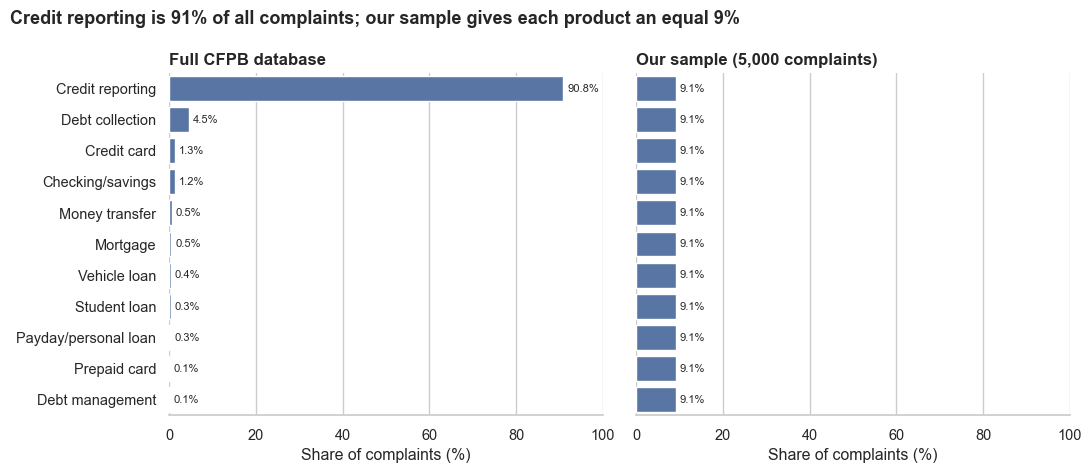

In [7]:
# Product counts shown on the CFPB complaint search page (all complaints, Oct 2026)
database_counts = pd.Series({
    "Credit reporting": 6_341_482, "Debt collection": 317_439, "Credit card": 92_750,
    "Checking/savings": 85_931, "Money transfer": 38_217, "Mortgage": 32_110,
    "Vehicle loan": 24_617, "Student loan": 19_519, "Payday/personal loan": 17_907,
    "Prepaid card": 6_122, "Debt management": 4_243,
})
# Convert counts to % shares so the full database and our sample can be compared on one scale
database_share = database_counts / database_counts.sum() * 100
sample_share = df["product_short"].value_counts(normalize=True) * 100

order = database_share.sort_values().index      # same product order in both panels

shares = pd.DataFrame({"Full CFPB database": database_share,
                       "Our sample (5,000 complaints)": sample_share}).reindex(order[::-1])

# Two side-by-side bar charts: full database (left) vs. our sample (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, column in zip(axes, shares.columns):
    sns.barplot(x=shares[column], y=shares.index, color=MAIN, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)   # write the % at the end of each bar
    ax.set(xlim=(0, 100), xlabel="Share of complaints (%)", ylabel="", title=column)

fig.suptitle("Credit reporting is 91% of all complaints; our sample gives each product an equal 9%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- Our sample is **balanced by design**: 454 or 455 complaints for each of the 11 products (table above).
- The real complaint stream is extremely imbalanced: credit reporting is about 91%, and the six smallest products are each under 0.5%. A model trained on raw data could score 91% accuracy by always guessing "credit reporting" and still be useless for routing.
- Because the sample is balanced, **accuracy is a fair headline metric**, and **macro F1** (which weights every product equally) shows whether small products are handled well.
- For Phase 3: a model trained on balanced data will over-predict small products when used on real traffic. We will note this and consider adjusting for real-world frequencies when interpreting results.

### 1.4 Coverage over time

In [8]:
# Number of complaints received in each month of the sample
per_month = df["month"].value_counts().sort_index()
print(per_month.to_string())

# Smallest count in the month x product table: if it is above 0, every product appears in every month
print(f"\nSmallest product-month cell: {pd.crosstab(df['month'], df['Product']).min().min()} complaints")

month
2025-08    418
2025-09    418
2025-10    418
2025-11    418
2025-12    418
2026-01    418
2026-02    418
2026-03    418
2026-04    418
2026-05    418
2026-06    413
2026-07    407
Freq: M

Smallest product-month cell: 37 complaints


- Every month from August 2025 to May 2026 has 418 complaints; June (413) and July (407) are slightly lower, likely because fewer recent narratives were published before the CFPB stopped publishing narratives in August 2026. Every product appears in every month (the smallest product-month count is 37), so no single month drives the patterns we find.

### 1.5 Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.

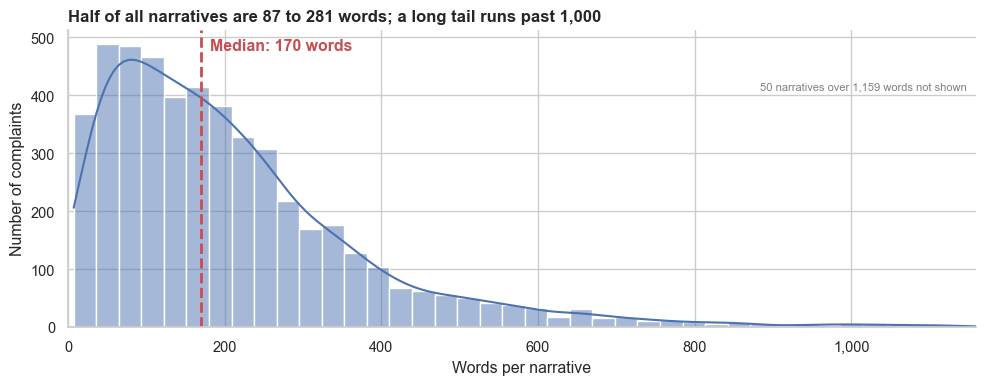

count    5000.0
mean      225.0
std       251.0
min         7.0
25%        87.0
50%       170.0
75%       281.0
max      5058.0
Under 50 words: 12%   Over 500 words: 7%


In [9]:
# Number of words in each narrative (helper column created by load_complaints)
words = df["word_count"]

# Plain (linear) axis: show the chart up to the 99th percentile so the long tail
# doesn't squash the bars; the statistics below still use every complaint
cap = words.quantile(0.99)
shown = words[words <= cap]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(shown, bins=40, color=MAIN, kde=True, ax=ax)   # bars = counts, line = smoothed shape
# Dashed line and label at the median
ax.axvline(words.median(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(words.median() + cap * 0.01, ax.get_ylim()[1] * 0.93, f"Median: {words.median():.0f} words",
        color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))   # 1,000 instead of 1000
ax.set(xlim=(0, cap), xlabel="Words per narrative", ylabel="Number of complaints",
       title="Half of all narratives are 87 to 281 words; a long tail runs past 1,000")
# Note on the chart how many long narratives fall outside the plotted range
ax.text(0.99, 0.80, f"{(words > cap).sum()} narratives over {cap:,.0f} words not shown",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
sns.despine()
plt.tight_layout()
plt.show()

# Summary statistics on ALL narratives, plus the share of very short and very long ones
print(words.describe().round(0).to_string())
print(f"Under 50 words: {(words < 50).mean():.0%}   Over 500 words: {(words > 500).mean():.0%}")

Complaint narrative lengths are right-skewed, with most complaints containing relatively short narratives and fewer complaints having very long narratives. The median narrative is 170 words, while the mean is higher at 225 words, and the longest runs to 5,058 words. This difference reflects a smaller number of very long complaints: 7% are over 500 words, while 12% are under 50 words.

For readability, the histogram displays narratives up to the 99th percentile. The full dataset, including longer narratives, is retained for the analysis. The variation in narrative length may be important when preprocessing the text and building the classification model.

### 1.6 Data quality: redactions and template letters

In [10]:
# Share of narratives containing CFPB redactions (two or more X's in a row, e.g. XXXX)
has_redaction = df[TEXT_COL].str.contains(r"X{2,}")
print(f"Narratives with redacted text (XXXX): {has_redaction.mean():.0%}")

# Narratives whose text appears more than once (template letters)
dupes = duplicate_narratives(df)
extra_copies = int((dupes["copies"] - 1).sum())   # copies beyond the first one of each letter
print(f"Narratives that appear more than once: {len(dupes)}  ({extra_copies} extra copies)")
dupes.head(5)   # the five most repeated letters

Narratives with redacted text (XXXX): 82%
Narratives that appear more than once: 44  (105 extra copies)


,copies,narrative_start
0,27,There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15...
1,13,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Repo..."
2,7,My rights were violated as a consumer under 15USC1681B and I need them blocked and deleted from my report ASAP...
3,7,I want to stress that I did not give written permission for these specific transactions to be included in my consumer re...
4,5,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to repor...


- **82% of narratives contain CFPB redactions** (`XXXX` for names, account numbers and dates). These are meaningless to a model, so the cleaning step will remove them before counting words.
- **105 rows are exact copies** of 44 template letters, mostly credit reporting disputes citing FCRA sections. If copies land in both the training and test sets, the model is tested on text it has already seen and its score is inflated. We remove the extra copies before modeling, leaving 4,895 unique narratives.

### 1.7 Example narratives (one per product)

In [11]:
# Display one sample complaint narrative per product (random_state fixes the sample so it is reproducible)
sample_complaints = (
    df[["Product", "Consumer complaint narrative"]]
    .groupby("Product")
    .sample(n=1, random_state=42)
    .sort_values("Product")
)

# Print the product and the first 500 characters of its narrative
for _, row in sample_complaints.iterrows():
    print("Product:", row["Product"])
    print("Narrative:", row["Consumer complaint narrative"][:500])
    print("-" * 80)

Product: Checking or savings account
Narrative: On XX/XX/year>2025, a teller at a Chase branch store stole {$1200.00} from my cash deposit while I was having a medical emergency. I am a type XXXX XXXX  and was experiencing XXXX XXXX XXXX  at the time, not feeling well. The teller noticed something was wrong, but instead of helping me, she took advantage of my condition and shorted my deposit. 

I tried filing a complaint with Chase immediately after the incident by calling the fraud department, and again on XX/XX/year>2025. Each time I was to
--------------------------------------------------------------------------------
Product: Credit card
Narrative: - I have been unable to log into my account for almost a year. Since XX/XX/XXXX. - I attempted to log in while on the phone with a Synchrony representative who confirmed that the information I was entering was correct, yet the system continued to reject it ; no technical ticket was opened and no remedy was provided to me outside of a re

The sample complaints vary in length and writing style, but they contain language that provides clues about the financial product involved. Some name the product outright ("my mortgage account", "private student loan", "my vehicle", "Amex giftcard"), while others only point to it through context, such as a company or service name (PayPal for money transfer, Cash App Borrow for a payday loan). The mortgage example is itself about credit reporting of a late payment, so a single complaint can touch more than one product.

This supports the use of text classification for categorizing unlabeled complaints, but it also highlights a potential concern: explicit product words may make some complaints easier to classify. We will examine this further in the modeling phase as part of our leakage and sanity checks.

## 2. Text mining

### 2.1 Preparing the text

Before counting words we (1) keep one copy of each duplicate narrative, so a template letter sent 27 times is not counted 27 times, and (2) clean each narrative with `clean_text` from `src/preprocessing.py`: lower-case, and remove CFPB redactions (`XXXX`), dollar amounts, numbers and punctuation.

For the simple word counts in 2.2 and 2.3 we use a second, stricter cleaning (`clean_for_counts`): lower-case, keep letters only, drop English stopwords and redaction placeholders, and lemmatize ("payments" → "payment"), so that counts group word forms together. These counts run on all 5,000 narratives.

In [12]:
# Remove duplicate template letters, then clean every narrative
text_df = drop_duplicate_narratives(df)                 # keep one copy of each template letter
text_df["clean"] = text_df[TEXT_COL].map(clean_text)   # cleaned text used for TF-IDF and sentiment checks
print(f"Unique narratives used for text mining: {len(text_df):,}")

# Before / after cleaning for one complaint
example = text_df.iloc[3]
print("\nBEFORE:", example[TEXT_COL][:300])
print("\nAFTER: ", example["clean"][:300])

Unique narratives used for text mining: 4,895

BEFORE: I am writing in response to your communication regarding the abovereferenced alleged debt. I dispute this debt in its entirety ( or, if applicable, I dispute the amount you claim is owed ) and request full validation under the Fair Debt Collection Practices Act ( FDCPA ), 15 U.S.C. 1692g.

Please pr

AFTER:  i am writing in response to your communication regarding the abovereferenced alleged debt i dispute this debt in its entirety or if applicable i dispute the amount you claim is owed and request full validation under the fair debt collection practices act fdcpa u s c g please provide in writing the n


In [13]:
# Stricter cleaning for raw word counts (stopwords removed, lemmatized)
stop_words = set(stopwords.words("english"))   # common English words such as "the", "and", "is"
lemmatizer = WordNetLemmatizer()               # reduces words to their base form ("payments" -> "payment")

def clean_for_counts(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Split text into individual words
    words = text.split()

    # Remove stopwords and redaction placeholders
    words = [
    word for word in words
    if word not in stop_words and not re.fullmatch(r"x+", word)
    ]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return " ".join(words)

# Apply stricter cleaning to unique narratives for word-frequency analysis
text_df["clean_narrative"] = text_df[TEXT_COL].apply(clean_for_counts)


### 2.2 Most common words and phrases across all complaints

We start with single words, then move to two-word phrases (bigrams), which carry more meaning.

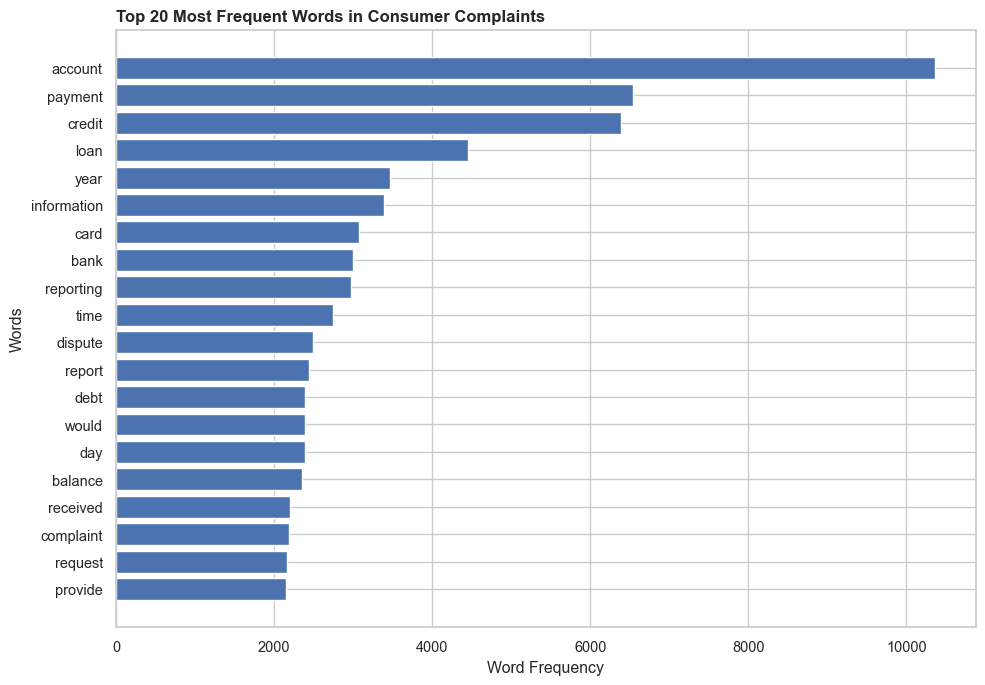

In [14]:
# Count the most common single words across all narratives

# Combine cleaned words from unique complaint narratives
all_words = " ".join(text_df["clean_narrative"]).split()
# Count how often each word appears
word_counts = Counter(all_words)   # Counter maps each word to the number of times it appears

# Get the 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)
# Plot the 20 most frequent words
plt.figure(figsize=(10, 7))

plt.barh(top_words["Word"], top_words["Frequency"])

plt.title("Top 20 Most Frequent Words in Consumer Complaints")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

# Display the most frequent word at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Interpretation

- **Account** is the most frequently used word, followed by **payment**, **credit**, and **loan**. These terms reflect common financial issues discussed in consumer complaints.
- Most of the frequently occurring words are general financial terms that appear across different product categories.
- Although individual words help us understand the main topics in complaints, they may not be enough to distinguish financial products. This is why we also examine bigrams and other text-mining techniques.

**Note:** This analysis uses 4,895 unique complaint narratives after removing duplicates to avoid counting repeated text multiple times.

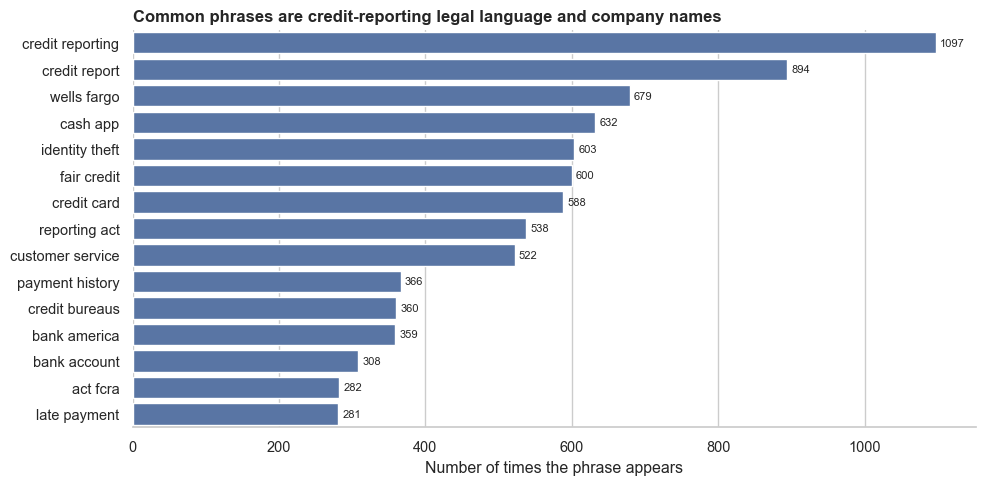

In [15]:
# Top 15 two-word phrases across all complaints
top_phrases = top_terms(text_df["clean"], n=15, ngram_range=(2, 2))   # ngram_range=(2, 2): two-word phrases only

# Horizontal bar chart, most frequent phrase at the top
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_phrases, x="count", y="term", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)   # write the count at the end of each bar
ax.set(xlabel="Number of times the phrase appears", ylabel="",
       title="Common phrases are credit-reporting legal language and company names")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- The two most frequent phrases are "credit reporting" (1,097) and "credit report" (894), and several others ("fair credit", "reporting act", "act fcra") come from **legal language about the Fair Credit Reporting Act**. Consumers in several products, not only credit reporting, quote this law, so these phrases alone will not separate products cleanly.
- **Company names** are among the most common phrases: "wells fargo" (679) and "cash app" (632) rank third and fourth, and "bank america" (359) also appears. A company usually points to a product (Cash App means money transfer), so the model may lean on them. That is useful for routing at one bank, but we will check in Phase 3 that the model is not relying on company names alone.
- "Identity theft" (603 mentions) is a major theme on its own.

### 2.3 The words that distinguish each product

**Raw counts first.** The most frequent words within each product:

In [16]:
# Get the most common words for a product category
def get_top_words_by_product(product, n=10):

    # Select cleaned narratives for the chosen product
    product_text = text_df.loc[
        text_df["Product"] == product, "clean_narrative"
    ]

    # Combine the narratives into individual words
    words = " ".join(product_text).split()

    # Count the words
    word_counts = Counter(words)

    # Return the most frequent words
    return pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )


# Get the top 5 words for each product category
product_word_summary = []

# Loop through all 11 financial product categories
for product in text_df["Product"].unique():

    top_words_product = get_top_words_by_product(product, n=5)

    product_word_summary.append({
        "Product": product,
        "Top 5 Words": ", ".join(top_words_product["Word"])
    })

# Display the summary
product_word_summary = pd.DataFrame(product_word_summary)

product_word_summary

,Product,Top 5 Words
0,Mortgage,"payment, mortgage, loan, account, year"
1,Debt or credit management,"account, credit, debt, payment, fee"
2,Debt collection,"account, debt, credit, reporting, collection"
3,Credit reporting or other personal consumer reports,"account, credit, reporting, information, report"
4,Credit card,"credit, account, card, payment, charge"
5,"Money transfer, virtual currency, or money service","account, transaction, fund, bank, app"
6,"Payday loan, title loan, personal loan, or advance loan","loan, payment, account, credit, year"
7,Vehicle loan or lease,"payment, vehicle, account, loan, credit"
8,Prepaid card,"card, account, transaction, fund, dispute"
9,Checking or savings account,"account, bank, fund, transaction, year"


Raw counts are dominated by words that are common everywhere: "account" is in the top 5 for all 11 products and "credit" for 7. A few product words do break through (*mortgage*, *vehicle*, *mohela*, *collection*, *app*), and mortgage complaints name their product directly, which supports the masking test planned for Phase 3.

**TF-IDF scores** fix this: they reward words that are frequent in a complaint but rare across all complaints, so the top TF-IDF words for each product are the ones that mark it out. These are the same features our Phase 3 classifier will use. Longer bars mean more distinctive words (bar lengths compare words within a product, not across products).

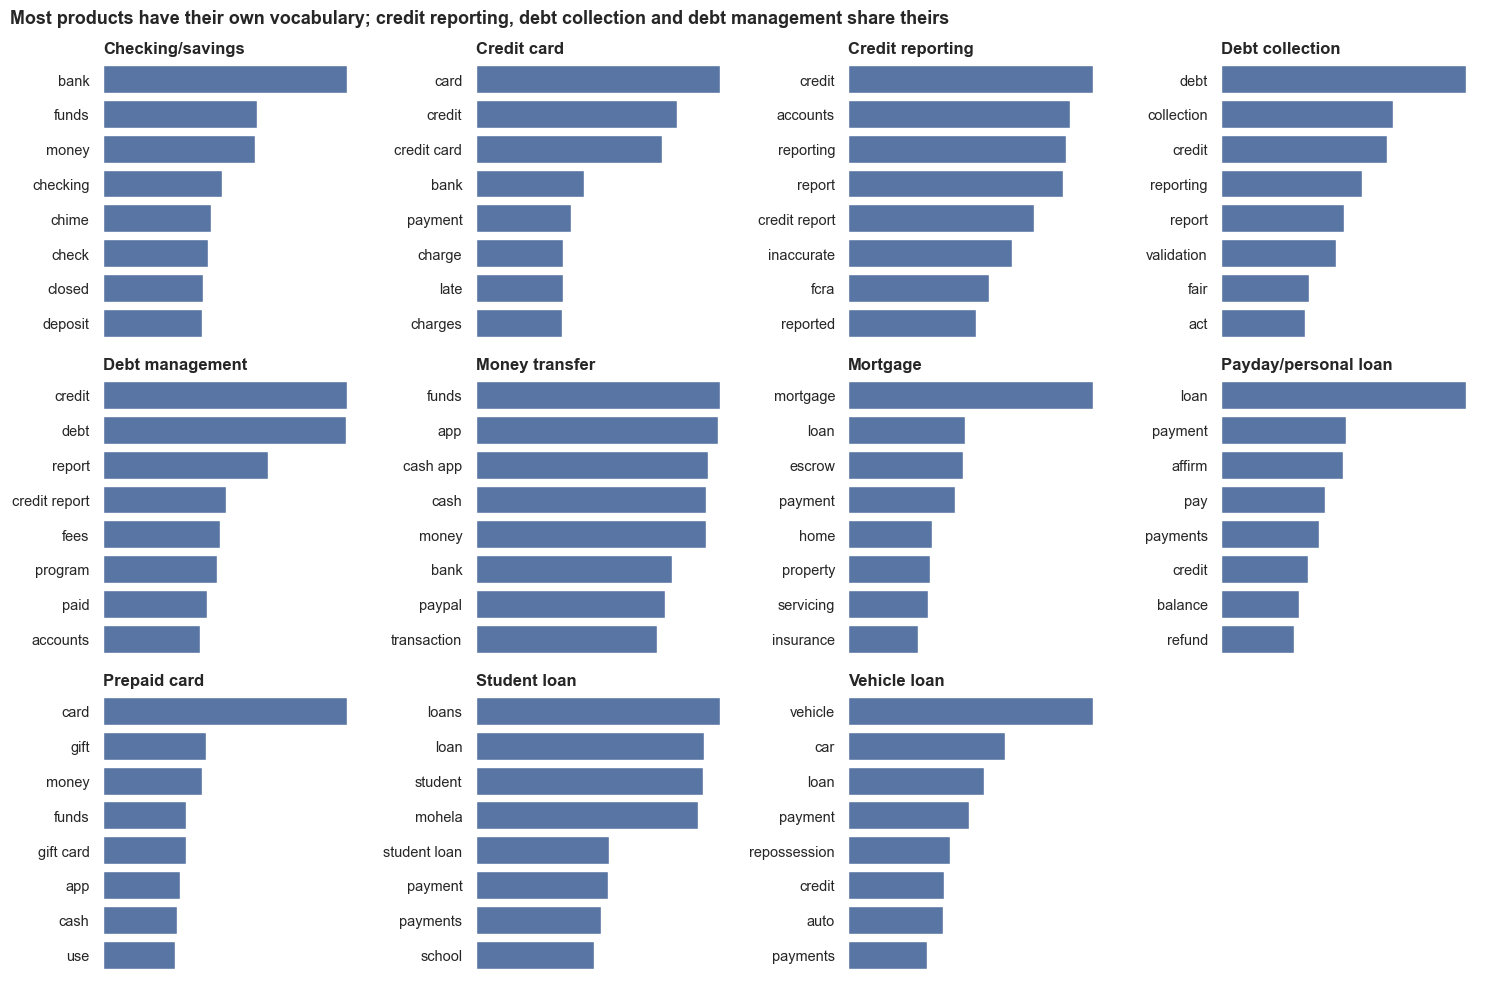

In [17]:
# Top 8 distinctive terms per product (highest average TF-IDF score)
distinct = distinctive_terms(text_df["clean"], text_df["product_short"], n=8)

# One small bar chart per product, arranged in a 3 x 4 grid
products = sorted(distinct["product"].unique())
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, product in zip(axes.flat, products):
    terms = distinct[distinct["product"] == product]   # this product's 8 terms
    sns.barplot(data=terms, x="score", y="term", color=MAIN, ax=ax)
    ax.set(title=product, xlabel="", ylabel="", xticks=[])   # scores only compare words within a product, so no x-axis
    sns.despine(ax=ax, left=True, bottom=True)
axes.flat[-1].axis("off")    # 11 products in a 12-slot grid: hide the empty one

fig.suptitle("Most products have their own vocabulary; credit reporting, debt collection and debt management share theirs",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

- **Eight products have clear, product-specific vocabulary:** mortgage (*escrow, property, servicing*), student loan (*school, mohela*), vehicle loan (*repossession, auto*), checking/savings (*deposit, check*), prepaid card (*gift card*). These should be easy to classify.
- **Credit reporting, debt collection and debt management share their top words** (*credit*, *report*). Debt management complaints are often about credit repair companies promising to fix a credit report, so their language overlaps with credit reporting. These categories share similar vocabulary, so we will examine whether the classification models confuse them more frequently in Phase 3.
- Company names show up as distinctive terms (*chime, mohela, affirm, paypal*). This confirms the point from 2.2: part of the signal is *who* the complaint is about, not just *what* it is about.

### 2.4 Word clouds: overlapping vs. distinct vocabulary

Word size shows how distinctive a word is for that product (TF-IDF). The three overlapping products sit beside mortgage, which has its own vocabulary.

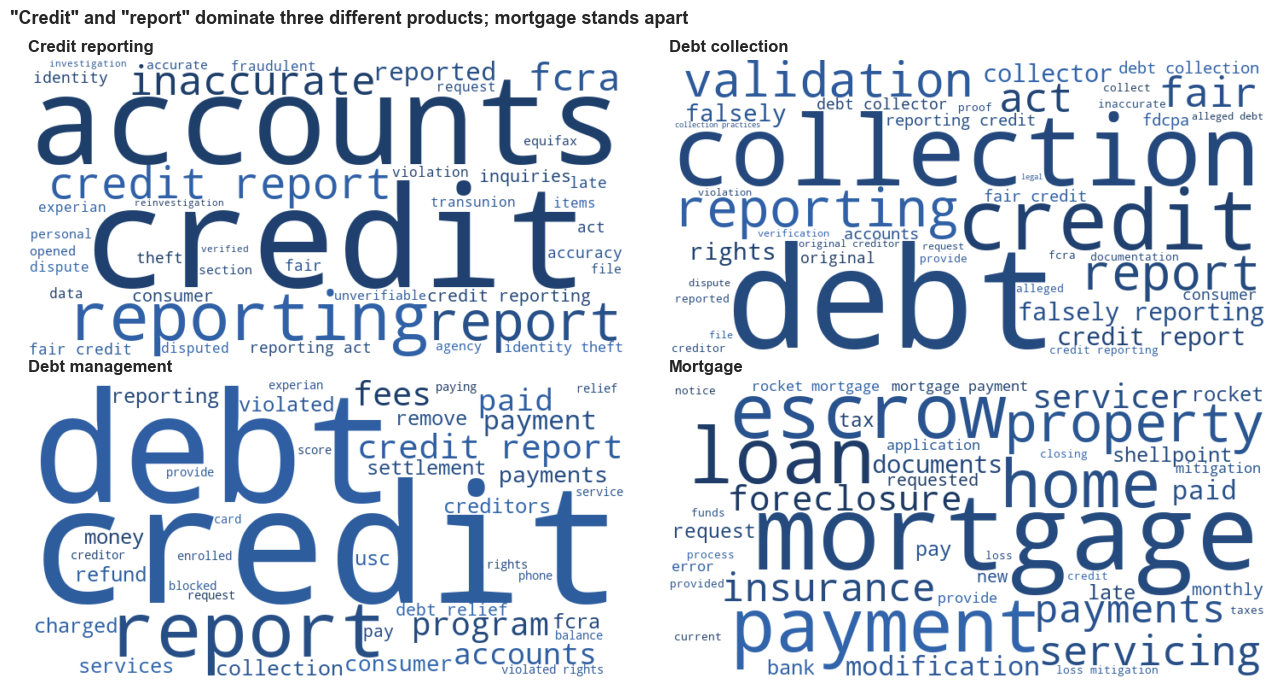

In [18]:
# Word clouds for the three overlapping products and one distinct product
cloud_products = ["Credit reporting", "Debt collection", "Debt management", "Mortgage"]
cloud_terms = distinctive_terms(text_df["clean"], text_df["product_short"], n=40)   # top 40 TF-IDF terms per product

def dark_blue(*args, **kwargs):
    # Colour every word in a readable dark blue (shades vary for texture)
    return f"hsl(215, 55%, {np.random.randint(25, 45)}%)"

# Draw one cloud per product in a 2 x 2 grid; word size = TF-IDF score
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, product in zip(axes.flat, cloud_products):
    weights = cloud_terms[cloud_terms["product"] == product].set_index("term")["score"].to_dict()   # {word: score}
    cloud = WordCloud(width=700, height=350, background_color="white", color_func=dark_blue,
                      prefer_horizontal=1.0, random_state=1).generate_from_frequencies(weights)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(product)
    ax.axis("off")   # hide the axes around the image

fig.suptitle('"Credit" and "report" dominate three different products; mortgage stands apart',
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The first three clouds are dominated by the same words (*credit, report, reporting, debt*), while the mortgage cloud shares almost none of them. For the routing team this means a complaint that talks about a credit report could belong to any of three teams; the deciding clues are smaller words such as *validation* (debt collection) or *program, fees* (debt management).

### 2.5 Vocabulary Overlap Across Financial Products (Jaccard Similarity)

We use Jaccard similarity to measure how much vocabulary is shared between financial product categories.

Jaccard similarity compares the number of shared words with the total number of unique words across two sets.

A score of 0 indicates no shared words, while a score of 1 indicates identical word sets.

This analysis helps us identify product categories with similar vocabulary and explore which categories might be more difficult to distinguish during predictive modeling.

In [19]:
# Get the 50 most common meaningful words for each financial product
top_words_by_product = {}

for product, group in text_df.groupby("Product"):

    # Combine the cleaned narratives and remove stopwords
    words = " ".join(group["clean"]).split()
    words = [word for word in words if word not in STOPWORDS]

    # Select the 50 most frequent words for each product
    word_counts = Counter(words)
    top_words_by_product[product] = set(
        word for word, count in word_counts.most_common(50)
    )

# Calculate Jaccard similarity between each pair of products
products = list(top_words_by_product.keys())

jaccard_matrix = pd.DataFrame(
    index=products,
    columns=products,
    dtype=float
)

for product_a in products:
    for product_b in products:
        words_a = top_words_by_product[product_a]
        words_b = top_words_by_product[product_b]

        # Count shared words and total unique words
        shared_words = len(words_a.intersection(words_b))
        total_unique_words = len(words_a.union(words_b))

        # Calculate Jaccard similarity
        jaccard_matrix.loc[product_a, product_b] = (
            shared_words / total_unique_words if total_unique_words else 0
        )

# Display the similarity scores
display(jaccard_matrix.round(2))

,Checking or savings account,Credit card,Credit reporting or other personal consumer reports,Debt collection,Debt or credit management,"Money transfer, virtual currency, or money service",Mortgage,"Payday loan, title loan, personal loan, or advance loan",Prepaid card,Student loan,Vehicle loan or lease
Checking or savings account,1.00,0.37,0.16,0.16,0.25,0.54,0.20,0.27,0.47,0.16,0.20
Credit card,0.37,1.00,0.19,0.22,0.39,0.32,0.25,0.45,0.32,0.25,0.35
Credit reporting or other personal consumer reports,0.16,0.19,1.00,0.47,0.27,0.10,0.11,0.20,0.09,0.16,0.23
Debt collection,0.16,0.22,0.47,1.00,0.37,0.14,0.16,0.32,0.12,0.20,0.33
Debt or credit management,0.25,0.39,0.27,0.37,1.00,0.23,0.28,0.45,0.20,0.33,0.39
"Money transfer, virtual currency, or money service",0.54,0.32,0.10,0.14,0.23,1.00,0.19,0.27,0.54,0.18,0.19
Mortgage,0.20,0.25,0.11,0.16,0.28,0.19,1.00,0.32,0.18,0.28,0.35
"Payday loan, title loan, personal loan, or advance loan",0.27,0.45,0.20,0.32,0.45,0.27,0.32,1.00,0.25,0.32,0.54
Prepaid card,0.47,0.32,0.09,0.12,0.20,0.54,0.18,0.25,1.00,0.14,0.16
Student loan,0.16,0.25,0.16,0.20,0.33,0.18,0.28,0.32,0.14,1.00,0.28


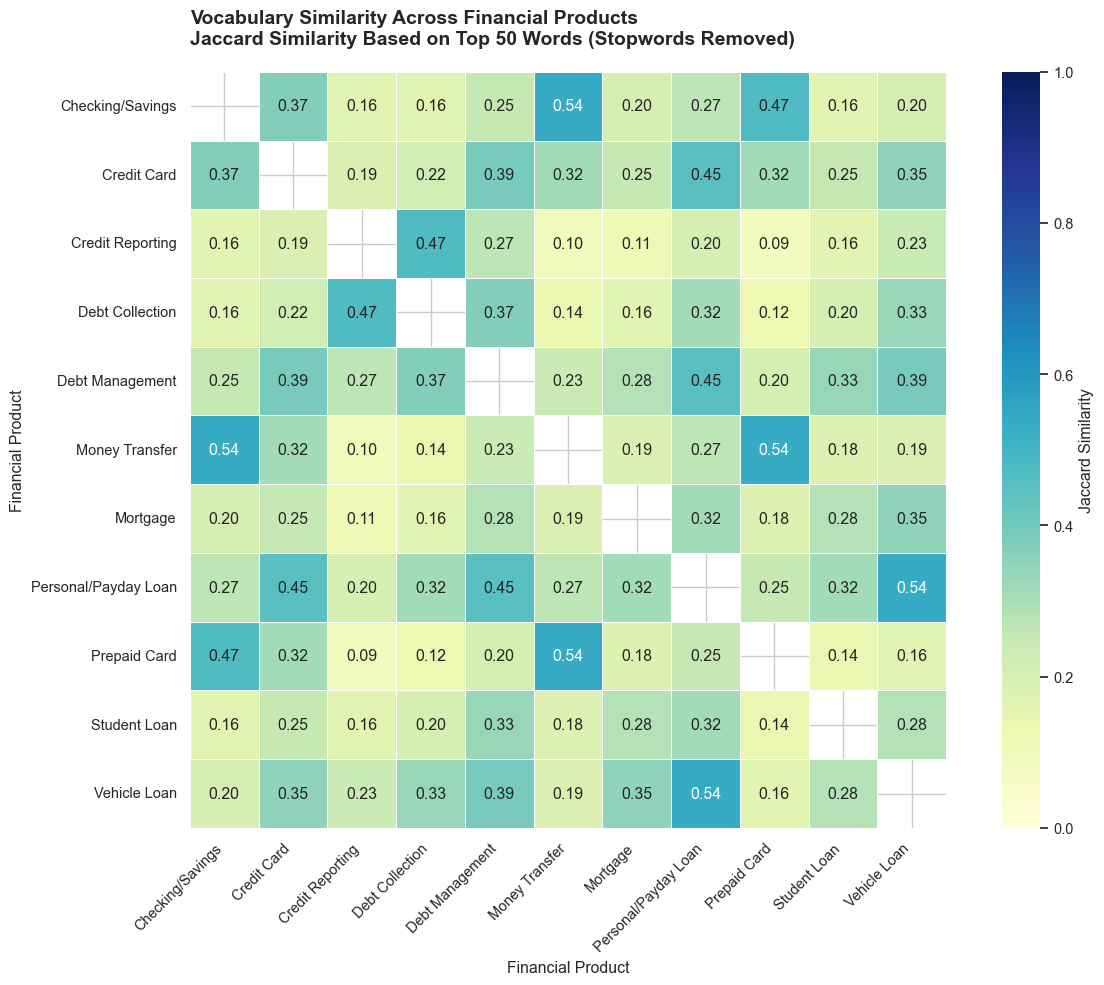

In [20]:
# Shorten product names to make the heatmap easier to read
short_names = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt Management",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Personal/Payday Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

# Apply shorter labels without changing the similarity scores
plot_matrix = jaccard_matrix.rename(
    index=short_names,
    columns=short_names
)

# Hide self-comparisons along the diagonal
mask = np.eye(len(plot_matrix), dtype=bool)

plt.figure(figsize=(13, 10))

sns.heatmap(
    plot_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Jaccard Similarity"}
)

plt.title(
    "Vocabulary Similarity Across Financial Products\n"
    "Jaccard Similarity Based on Top 50 Words (Stopwords Removed)",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Financial Product")
plt.ylabel("Financial Product")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation: Vocabulary Similarity Across Financial Products

The Jaccard similarity analysis compares the 50 most frequent words in each financial product category after removing stopwords.

- **Highest similarity (0.54):** Checking/Savings and Money Transfer, Money Transfer and Prepaid Card, and Personal/Payday Loan and Vehicle Loan share the most vocabulary. This makes sense because these products involve related financial activities.

- **Lowest similarity (0.09):** Credit Reporting and Prepaid Card have the least vocabulary overlap, suggesting that consumers use different language when describing problems with these products.

- **Credit Reporting and Debt Collection (0.47):** These categories share several common terms, which may make them harder for classification models to distinguish.

Overall, the results show that some financial products have distinct vocabularies, while others share similar language. This overlap may help explain potential classification errors when we evaluate our models in Phase 3.

### 2.6 Do complaints name their own product?

If most complaints simply say "my mortgage" or "my student loan", classification is easy but partly trivial. The chart shows, for complaints of each product (rows), the share that mention the key words of each product (columns). Numbers on the outlined diagonal mean complaints name their own product; strong numbers off the diagonal mean they mention another product's words.

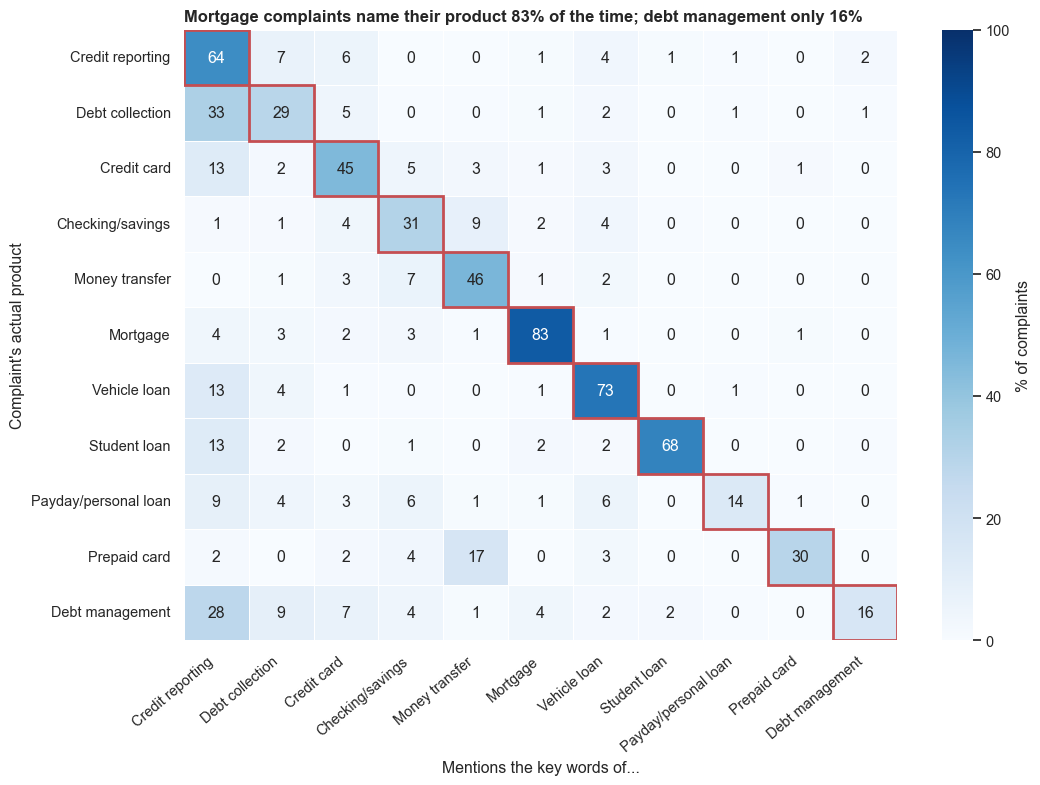

In [21]:
# % of complaints in each product (rows) that mention each product's key words (columns)
mentions = product_word_matrix(text_df)

# Heatmap: rows = actual product, columns = product whose key words are mentioned, cell = % of complaints
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mentions, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% of complaints"}, ax=ax)
ax.set(xlabel="Mentions the key words of...", ylabel="Complaint's actual product",
       title="Mortgage complaints name their product 83% of the time; debt management only 16%")

# Outline the diagonal: complaints mentioning their own product's words
for i in range(len(mentions)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2))
plt.xticks(rotation=40, ha="right")   # tilt column names so they do not overlap
plt.tight_layout()
plt.show()

- **Some products almost always name themselves:** mortgage (83%), vehicle loan (73%), student loan (68%) and credit reporting (64%). For these, a model can score well just by spotting the product word, which is why Phase 3 will **re-test the model with these words masked** to see how much accuracy depends on them.
- **Others rarely do:** only 14% of payday/personal loan and 16% of debt management complaints use their own product's words. These classes depend on indirect clues and will likely be harder.
- **The key off-diagonal finding:** 33% of debt collection complaints and 28% of debt management complaints use credit-reporting words, as much as or more than their own. This matches 2.3 and 2.4: credit reporting, debt collection and debt management are the classes we expect the model to confuse, and the cases where the routing team would most benefit from a second look.

### 2.7 Sentiment Analysis Using VADER

We use VADER sentiment analysis to examine the emotional tone of consumer complaint narratives. VADER assigns sentiment scores based on the words and expressions in a text.

This analysis will help us understand the overall sentiment of complaints and compare sentiment across financial product categories.

In [22]:
# Baseline VADER score for every complaint
text_df["sentiment_raw"] = sentiment_scores(text_df[TEXT_COL])            # compound score from -1 to +1
text_df["label_raw"] = sentiment_label(text_df["sentiment_raw"])          # Negative < -0.05 <= Neutral <= 0.05 < Positive

# Share of complaints in each sentiment label
print("Share of complaints by sentiment label (baseline VADER):")
print((text_df["label_raw"].value_counts(normalize=True) * 100).round(1).to_string())

Share of complaints by sentiment label (baseline VADER):
label_raw
Negative    60.1
Positive    36.0
Neutral      3.9


- VADER calls about **36% of complaints positive**, even though every narrative here is a complaint. To find out why, we add up which positive dictionary words contribute most across all complaints.

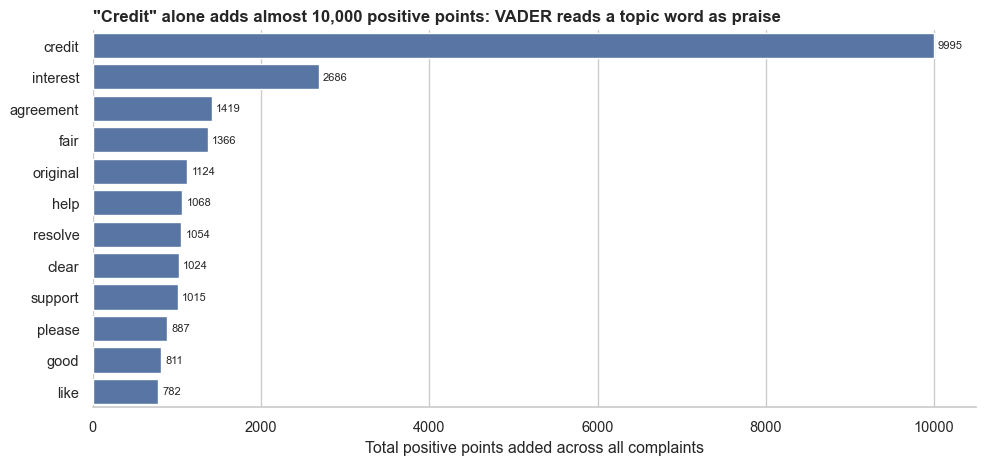

In [23]:
# Positive dictionary words that add the most to VADER scores
contributions = positive_word_contributions(text_df["clean"], n=12)   # top 12 words by total positive score added

# Horizontal bar chart of those words
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=contributions, x="positive_points", y="word", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)
ax.set(xlabel="Total positive points added across all complaints", ylabel="",
       title='"Credit" alone adds almost 10,000 positive points: VADER reads a topic word as praise')
sns.despine(left=True)
plt.tight_layout()
plt.show()

- VADER was built for social media, where *credit* means praise ("give credit") and *interest* means curiosity. In financial complaints these are **topic words**: *credit report*, *interest rate*, the **Fair** Credit Reporting Act, a loan **agreement**, even **Wells** Fargo. They inflate scores, most of all for credit-related products.

**Domain-adjusted sentiment analysis:** We make selected financial terms neutral in VADER's dictionary (`FINANCE_WORDS` in `src/text_analysis.py`) and calculate sentiment scores again. This is an experimental adjustment to reduce the influence of financial terminology, not a guaranteed improvement in sentiment accuracy.


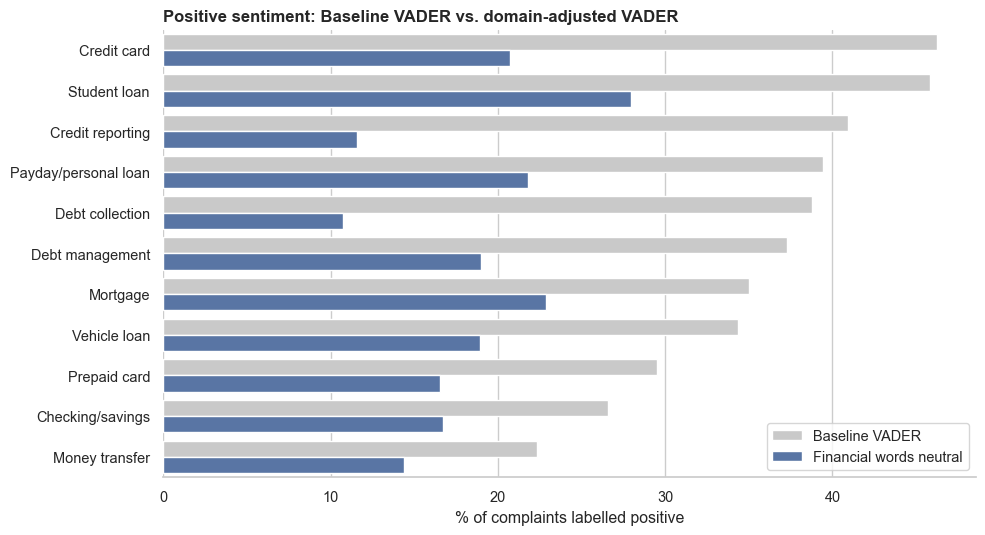

Overall share labelled positive: baseline 36%, domain-adjusted 18%


In [24]:
# Re-score with financial topic words made neutral
text_df["sentiment"] = sentiment_scores(text_df[TEXT_COL], neutral_words=FINANCE_WORDS)   # FINANCE_WORDS scored as 0
text_df["label"] = sentiment_label(text_df["sentiment"])

# Compare positive sentiment percentages before and after domain adjustment
positive_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
    "Financial words neutral": text_df["label"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
}).sort_values("Baseline VADER", ascending=False)

# Reshape to long format (one row per product and version) so seaborn can draw paired bars
plot_data = positive_share.reset_index().melt(id_vars="product_short", var_name="version",
                                              value_name="pct_positive")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="pct_positive", y="product_short", hue="version",
            palette=["#c9c9c9", MAIN], ax=ax)
ax.set(xlabel="% of complaints labelled positive", ylabel="",
       title="Positive sentiment: Baseline VADER vs. domain-adjusted VADER")
ax.legend(title="", loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Compare the overall share of positive sentiment before and after domain adjustment
print("Overall share labelled positive:",
      f"baseline {text_df['label_raw'].eq('Positive').mean():.0%},",
      f"domain-adjusted {text_df['label'].eq('Positive').mean():.0%}")


- After making selected financial terms neutral, VADER classified approximately **77% of complaints as negative**, compared with the baseline results.
- The percentage classified as positive decreased, especially for credit reporting, debt collection, and credit card complaints.
- About **18% of complaints still received positive sentiment labels**. Words such as *help*, *resolve*, *support*, and *please* may contribute to these scores even when consumers are describing problems.
- **Takeaway:** Domain-specific terminology can influence sentiment scores. However, this adjustment is experimental, and we would need manually labeled sentiment data to determine whether it improves accuracy.


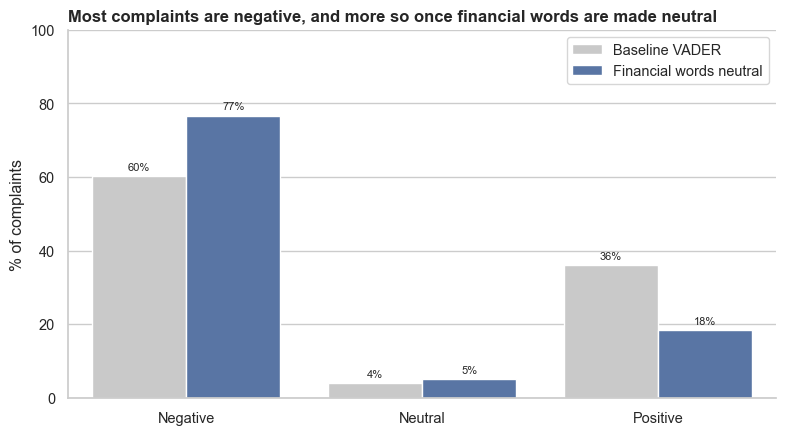

          Baseline VADER  Financial words neutral
Negative            60.1                     76.6
Neutral              3.9                      5.0
Positive            36.0                     18.4


In [25]:
# Share of complaints by sentiment label: baseline VADER vs. financial words neutral
order = ["Negative", "Neutral", "Positive"]   # fixed order for the x-axis
label_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].value_counts(normalize=True) * 100,
    "Financial words neutral": text_df["label"].value_counts(normalize=True) * 100,
}).reindex(order)

# Reshape to long format (one row per label and version) for paired bars
plot_data = label_share.reset_index(names="sentiment").melt(id_vars="sentiment", var_name="version",
                                                            value_name="pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_data, x="sentiment", y="pct", hue="version", order=order,
            palette=["#c9c9c9", MAIN], ax=ax)
for container in ax.containers:   # write the % above every bar
    ax.bar_label(container, fmt="%.0f%%", padding=3, fontsize=8)
ax.set(xlabel="", ylabel="% of complaints", ylim=(0, 100),
       title="Most complaints are negative, and more so once financial words are made neutral")
ax.legend(title="", loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

print(label_share.round(1).to_string())

- With baseline VADER, **60% of complaints are negative, 36% positive and 4% neutral**. Since every narrative is a complaint, a positive share this high is a warning sign.
- After financial topic words (*credit*, *interest*, *fair*, *agreement*) are made neutral, **77% of complaints are negative and 18% positive**. Almost all of the change moves from positive to negative; the neutral share stays small (4% to 5%).

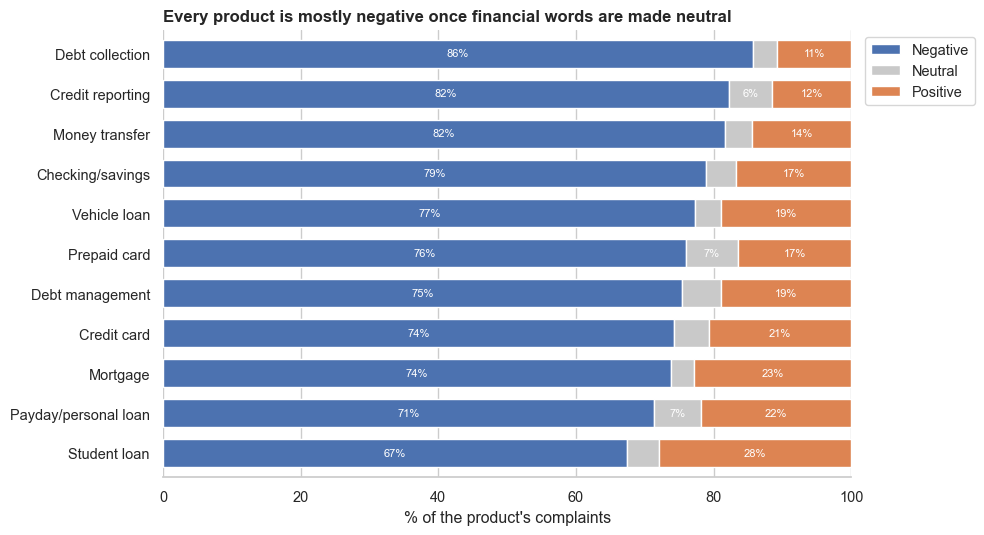

label                 Negative  Neutral  Positive
product_short                                    
Debt collection           85.6      3.6      10.8
Credit reporting          82.2      6.3      11.6
Money transfer            81.6      4.0      14.4
Checking/savings          78.9      4.4      16.7
Vehicle loan              77.3      3.7      18.9
Prepaid card              76.0      7.5      16.5
Debt management           75.4      5.6      19.0
Credit card               74.2      5.1      20.7
Mortgage                  73.8      3.3      22.9
Payday/personal loan      71.4      6.8      21.8
Student loan              67.4      4.6      28.0


In [26]:
# Negative / neutral / positive mix for each product (financial words neutral)
# % of each product's complaints in each label (each row adds up to 100)
sentiment_by_product = (pd.crosstab(text_df["product_short"], text_df["label"], normalize="index") * 100)
sentiment_by_product = sentiment_by_product[["Negative", "Neutral", "Positive"]].sort_values("Negative")

# One stacked bar per product: negative + neutral + positive = 100%
ax = sentiment_by_product.plot(kind="barh", stacked=True, figsize=(10, 5.5), width=0.7,
                               color=["#4c72b0", "#c9c9c9", "#dd8452"])
# Label each segment with its %, skipping segments under 6% that are too narrow to read
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color="white")
ax.set(xlim=(0, 100), xlabel="% of the product's complaints", ylabel="",
       title="Every product is mostly negative once financial words are made neutral")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(sentiment_by_product.round(1).sort_values("Negative", ascending=False).to_string())

- **Every product is mostly negative** once financial words are made neutral. Debt collection has the highest negative share (86%) and student loan the lowest (67%, with the highest positive share at 28%).
- Debt collection and credit reporting have some of the highest negative sentiment percentages after the domain adjustment. Their positive sentiment percentages decreased substantially, suggesting that financial terminology influenced the original VADER scores. However, we cannot confirm that the original positive labels were incorrect without manually reviewing and labeling the complaints.

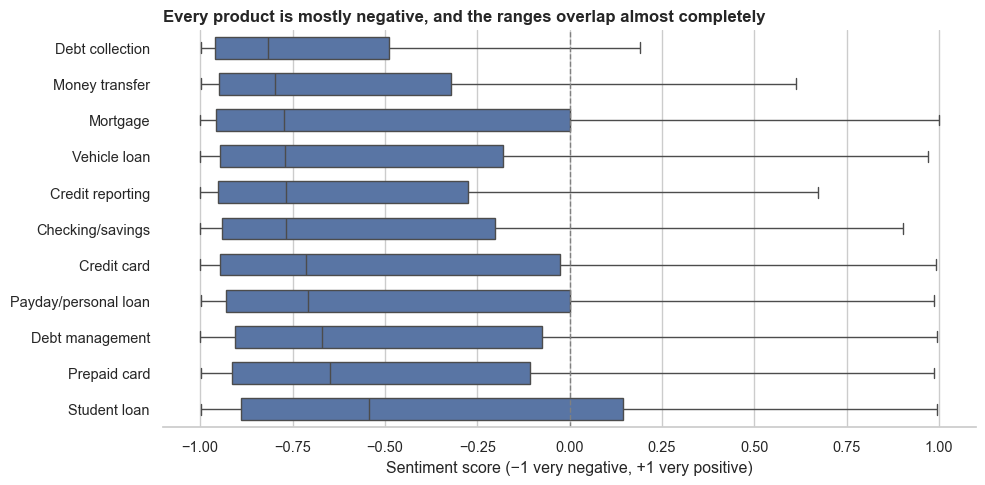

                              median  count
Company response to consumer               
Closed with explanation        -0.74   3971
Other                          -0.36    201
Relief given                   -0.75    723


In [27]:
# Does sentiment differ by product? (adjusted scores)
# Products ordered from most negative to least negative median score
order_by_sentiment = text_df.groupby("product_short")["sentiment"].median().sort_values().index

# Box = middle half of scores, line = median, whiskers = typical range (outliers hidden)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=text_df, x="sentiment", y="product_short", order=order_by_sentiment,
            color=MAIN, showfliers=False, width=0.6, ax=ax)
ax.axvline(0, color="grey", linewidth=1, linestyle="--")   # neutral line
ax.set(xlabel="Sentiment score (−1 very negative, +1 very positive)", ylabel="",
       title="Every product is mostly negative, and the ranges overlap almost completely")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Does sentiment differ by how the company responded?
# Group company responses into three outcomes, then compare median sentiment and counts
outcome = text_df["Company response to consumer"].map(
    lambda r: "Relief given" if "relief" in r else ("Closed with explanation" if "explanation" in r else "Other"))
print(text_df.groupby(outcome)["sentiment"].agg(["median", "count"]).round(2))

- Median sentiment ranges only from about −0.8 (debt collection, money transfer) to −0.5 (student loan), and the boxes overlap heavily. **Sentiment will not help the model tell products apart**, so we will not use it as a classification feature in Phase 3.
- Sentiment is also the same whether the company gave relief or just closed with an explanation (both about −0.75). So for our stretch question, *how angry* a consumer sounds does not predict *whether they get relief*.
- Where sentiment could still help is in **prioritising** within a team's queue (the most negative complaints first). If we need a reliable severity or urgency score, Claude can judge it from context, which a word list cannot. We will test that in our Phase 3 plan.

### 2.8 Summary: what Phase 2 means for Phase 3

| Finding | Evidence | Phase 3 action |
|---|---|---|
| Balanced sample (454–455 per product); real complaints are 91% credit reporting | 1.3 | Report accuracy and macro F1; note that a balanced model over-predicts small products on real traffic |
| 105 exact copies of 44 template letters | 1.6 | Remove copies before the train/test split (4,895 narratives) |
| Most products have their own vocabulary | 2.3, 2.4 | TF-IDF features with logistic regression as the baseline |
| Credit reporting, debt collection and debt management share vocabulary | 2.3–2.5 | Per-class precision and recall, and a confusion matrix |
| Many complaints name their own product (mortgage 83%) | 2.6 | Re-train with product words masked and compare macro F1 |
| Company names are among the most common and distinctive terms | 2.2, 2.3 | Inspect top features; test a version with company names removed |
| Sentiment is mostly negative for every product and overlaps across products | 2.7 | Do not use sentiment as a classification feature |

## 3. Predictive modeling

**Goal.** Predict the **Product** (11 categories, Y) from the **Consumer complaint narrative** (X), so that complaints arriving without a product label (emails, chat messages, call transcripts) can be routed to the right team. The CFPB data, where every narrative comes with the product the consumer chose, is our labelled training data.

### How we measure success

**Accuracy** is our main measure: the share of complaints sent to the right team. Because errors cost different teams in different ways, we also look at each product team's outcomes:

| Outcome, for one product team (say, Mortgage) | What it means for routing |
|---|---|
| **True positive (TP)** | A mortgage complaint is sent to the mortgage team |
| **False positive (FP)** | The mortgage team receives a complaint about another product: extra work for the team, and that consumer waits while it is re-routed |
| **False negative (FN)** | A mortgage complaint is sent to another team: the mortgage team never sees it, risking the response deadline |
| **True negative (TN)** | A complaint about another product is correctly kept away from the mortgage team |

From these counts: **precision** = TP / (TP + FP), how much of what a team receives is really theirs; **recall** = TP / (TP + FN), how much of a team's work actually reaches them; **specificity** = TN / (TN + FP), how well other products are kept away; **F1** combines precision and recall. Macro averages weight all 11 products equally.

### Four models, plus a baseline

| # | Model | Why it is a candidate |
|---|---|---|
| 0 | Majority-class baseline | The floor any useful model must beat |
| 1 | TF-IDF + logistic regression | Learns which words point to each product; one multinomial model fits all 11 products at once, with one set of coefficients and a probability per product |
| 2 | TF-IDF + linear SVM | Usually the strongest linear model for text |
| 3 | Embedding similarity with Claude-written product descriptions | Our instructor's suggestion (class 6, Exercise 3): no trained model, so possibly cheaper |
| 4 | Claude zero-shot (Haiku 5.5) | An LLM reads each complaint and names the product, with no training |

### How every value in this section is chosen

| Value | How it is chosen |
|---|---|
| 70/30 split | Set in our proposal; leaves at least 119 complaints per product for testing |
| 5-fold cross-validation, random seed 42 | Standard practice; the same folds are used for every comparison, so differences come from the models |
| TF-IDF and classifier settings | scikit-learn's defaults, unchanged (no tuning; see 3.6) |
| How many sample complaints Claude reads per product (model 3) | Compared 5, 10 and 20 on training complaints (3.4) |
| Final model | The rule below, applied to cross-validated scores |
| Words masked in the leakage check | Every word in the CFPB product and sub-product names (3.10) |
| Groups in the fairness check | Consumer tags in the data, and quartiles of narrative length (3.12) |
| Hand-check size (30 complaints) | Set by the project brief |

**How choices are made:**
- **Model 3's only setting** (k) takes the value with the highest accuracy on training complaints Claude did not see.
- **The final model** is the model with the highest accuracy on the training data (cross-validated for models 1 and 2), with one exception decided in advance: if logistic regression is within **one standard error** of the best (a difference within the noise between folds), we choose logistic regression, because only it gives the probabilities that routing needs (3.11).

### 3.1 Train/test split

We split 70% / 30%, as set in our proposal, **stratified** by product so every product has the same share in both sets. The test set is not touched again until 3.7.

In [31]:
SEED = 42   # fixed random seed, so every run gives the same split and results

# Stratified 70/30 split of the unique, cleaned narratives (text_df from 2.1):
# every product keeps the same share in the training and test sets
train_df, test_df = train_test_split(text_df, test_size=0.30, stratify=text_df["Product"], random_state=SEED)

X_train, y_train = train_df["clean"], train_df["Product"]
X_test, y_test = test_df["clean"], test_df["Product"]

print(f"Training: {len(train_df):,} complaints   Test: {len(test_df):,} complaints")
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).rename(index=SHORT_NAMES)

Training: 3,426 complaints   Test: 1,469 complaints


,train,test
Product,,
Checking/savings,318,137
Credit card,318,136
Credit reporting,279,119
Debt collection,292,126
Debt management,313,135
Money transfer,316,136
Mortgage,318,136
Payday/personal loan,318,136
Prepaid card,318,136


Every product has 119 to 137 complaints in the test set, so each class is evaluated on enough examples. Credit reporting has the fewest (119) because most of the removed duplicate letters were credit reporting disputes.

### 3.2 Majority-class baseline

A model that ignores the text and always predicts the most common product. Any useful model must beat it by a wide margin.

In [29]:
# Always predict the most common product in the training data
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print(f"Always predicts: {baseline_pred[0]}")
print(f"Test accuracy: {accuracy_score(y_test, baseline_pred):.1%}   "
      f"Test macro F1: {f1_score(y_test, baseline_pred, average='macro'):.3f}")

Always predicts: Checking or savings account
Test accuracy: 9.3%   Test macro F1: 0.016


Because the sample is balanced, the baseline is right only **9.3%** of the time (about 1 in 11), with a macro F1 of 0.016. On real complaint traffic, where 91% of complaints are credit reporting (1.3), the same baseline would score 91% accuracy while sending every other product to the wrong team. This is why we report macro F1 alongside accuracy.

### Evaluation tools used throughout section 3

In [32]:
DATA_DIR = Path(DATA_PATH).parent                         # Claude's answers are saved next to the data
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)  # the same 5 folds for every comparison


def routing_table(y_true, y_pred):
    # One row per product: TP, FP, FN, TN and the rates built from them
    labels = sorted(pd.unique(y_true))
    cm = confusion_matrix(y_true, y_pred, labels=labels)       # rows = true product, columns = predicted
    tp = np.diag(cm)                                             # correct predictions for each product
    fp = cm.sum(axis=0) - tp                                     # predicted as this product but wrong
    fn = np.bincount(pd.Categorical(y_true, categories=labels).codes, minlength=len(labels)) - tp
    # fn: complaints of this product predicted as something else (incl. off-list Claude answers)
    tn = len(y_true) - tp - fp - fn                              # everything else
    table = pd.DataFrame({"TP": tp, "FP": fp, "FN": fn, "TN": tn}, index=labels)
    table["precision"] = (table["TP"] / (table["TP"] + table["FP"])).fillna(0)
    table["recall"] = table["TP"] / (table["TP"] + table["FN"])
    table["specificity"] = table["TN"] / (table["TN"] + table["FP"])
    table["F1"] = (2 * table["precision"] * table["recall"] / (table["precision"] + table["recall"])).fillna(0)
    return table


def summary(y_true, y_pred):
    # Accuracy plus the macro (equal-weight) averages of the per-product rates
    table = routing_table(y_true, y_pred)
    return {"accuracy": accuracy_score(y_true, y_pred),
            **{f"macro {m}": table[m].mean() for m in ["precision", "recall", "specificity", "F1"]}}


def cv_scores(pipeline):
    # 5-fold cross-validated accuracy (mean and standard error) and macro F1, on the training set only
    r = cross_validate(pipeline, X_train, y_train, cv=CV, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    return {"CV accuracy": r["test_accuracy"].mean(),
            "standard error": r["test_accuracy"].std() / np.sqrt(len(r["test_accuracy"])),
            "CV macro F1": r["test_f1_macro"].mean()}

### Claude API tools used in sections 3 and 4

All the code that talks to Claude is in the cell below, so the notebook does not depend on a separate file. It holds:
- the **models** and their **prices** (for the cost table in 4.6);
- the **three prompts**: product descriptions (model 3), zero-shot classification (model 4) and error analysis (4.4);
- small functions that send the prompts, read the answers and **save every answer to a CSV in `Data/`**, so the notebook re-runs without an API key and without paying again.

The API key is read from the `.env` file (`ANTHROPIC_API_KEY`), which is listed in `.gitignore`, and is never printed.

In [37]:
# ======================================================================
# CLAUDE API TOOLS
# This cell only DEFINES settings, prompts and functions; it sends nothing to Claude.
# Claude is only called later, in 3.4 (model 3), 3.5 (model 4) and 4.4 (error analysis).
# Safety for our budget:
#   1. Every answer is saved to a CSV in Data/; if the CSV exists, Claude is never called again.
#   2. Before any batch is sent, its worst-case cost is estimated; if that would take total
#      spending over BUDGET_USD, the batch is NOT sent.
#   3. Every batch actually sent is recorded in Data/claude_spend_log.csv (date, task, tokens, cost).
# ======================================================================

# Settings
# Spending cap for this notebook. The team has $25 for the whole project; this notebook should cost
# about $1.50 in total, so $5 leaves room for one re-run without risking the rest of the budget
BUDGET_USD = 5.00

# File where every paid batch is recorded (committed to GitHub, so both team members see the total)
SPEND_LOG = DATA_DIR / "claude_spend_log.csv"

# The two Claude models we use: a small low-cost one and a larger, stronger one
CLAUDE_MODELS = {"Haiku 5.5": "claude-haiku-5-5", "Sonnet 5.5": "claude-sonnet-5-5"}

# Price in USD per million (input, output) tokens, from the model pages (November 2026):
# https://platform.claude.com/docs/en/models/haiku-5-5/overview  (rate for prompts under 100,000 tokens)
# https://www.anthropic.com/claude/sonnet
PRICES = {"claude-haiku-5-5": (0.10, 0.50), "claude-sonnet-5-5": (2.00, 10.00)}

# How many requests are sent at the same time (speeds up the run; lower it if the API reports rate limits)
PARALLEL_REQUESTS = 8

# The 11 official CFPB product names, taken from the data and listed in every prompt
PRODUCTS = sorted(text_df["Product"].unique())
CATEGORY_LIST = "\n".join(f"- {p}" for p in PRODUCTS)   # one product per line, as a bullet list

# ---------- Prompts ----------
# Prompt 1 (model 3): Claude reads k sample training complaints for ONE product
# and writes a short description of that product for a routing guide
DESCRIBE_PROMPT = """Below are {k} consumer complaints that were filed under the financial product category "{product}".

{samples}

Write a description of this product category for a complaint-routing guide: the kinds of accounts, problems and situations that complaints in this category describe. Use 3 to 5 plain sentences. Do not quote or summarise individual complaints, and do not mention the other categories."""

# Prompt 2 (model 4): Claude names the product of one complaint, with no training on our data
CLASSIFY_PROMPT = """You route consumer financial complaints to the right product team.

Product categories:
{categories}

Complaint:
<complaint>
{complaint}
</complaint>

Which ONE product category is this complaint about? Reply with the category name exactly as written above, and nothing else."""

# Prompt 3 (4.4): Claude reviews a complaint our model got wrong.
# Claude is NOT told the consumer's label or our model's prediction, so it cannot just agree with either
EXPLAIN_PROMPT = """Read the following consumer financial complaint and identify the most appropriate financial product category from the 11 categories provided.

Product categories:
{categories}

Complaint:
<complaint>
{complaint}
</complaint>

Answer on three lines:
CATEGORY: the category name exactly as written above
AMBIGUOUS: YES if the complaint could reasonably belong to more than one category, otherwise NO
CLUES: one or two sentences naming the words or context in the complaint that point to this category"""


# ---------- Cost: price, spending so far, and the budget check ----------
def cost_usd(input_tokens, output_tokens, model):
    # Dollar cost of a number of tokens for one model, at the prices above
    price_in, price_out = PRICES[model]
    return input_tokens / 1e6 * price_in + output_tokens / 1e6 * price_out


def spent_so_far():
    # Total dollars recorded in the spend log (0 if nothing has been spent yet)
    if not SPEND_LOG.exists():
        return 0.0
    return pd.read_csv(SPEND_LOG)["cost_usd"].sum()


def check_budget(prompts, model, max_tokens, task_name):
     # ~3 characters per token for these complaints (redactions like XXXX and numbers use more tokens),
    # plus a 50% safety margin, so the estimate stays above the real cost (checked on the first run: 4 was too low)
    est_in = sum(len(p) for p in prompts) / 3 * 1.5
    est_out = len(prompts) * max_tokens
    estimate = cost_usd(est_in, est_out, model)
    already = spent_so_far()
    print(f"{task_name}: {len(prompts):,} requests to {model}, at most ${estimate:.2f} "
          f"(spent so far ${already:.2f} of ${BUDGET_USD:.2f})")
    if already + estimate > BUDGET_USD:
        raise RuntimeError(f"Stopped before sending: ${already:.2f} + ${estimate:.2f} would exceed the "
                           f"${BUDGET_USD:.2f} budget. Nothing was sent and nothing was charged.")


def log_spending(task_name, model, results):
    # Add one line to the spend log with the REAL tokens and cost of a batch that was sent
    tokens_in = sum(r[1] for r in results)
    tokens_out = sum(r[2] for r in results)
    row = pd.DataFrame([{"date": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "task": task_name,
                         "model": model, "requests": len(results), "input_tokens": tokens_in,
                         "output_tokens": tokens_out, "cost_usd": round(cost_usd(tokens_in, tokens_out, model), 4)}])
    row.to_csv(SPEND_LOG, mode="a", header=not SPEND_LOG.exists(), index=False)
    print(f"Done: actual cost ${row['cost_usd'].iloc[0]:.2f}; total spent ${spent_so_far():.2f}")


# ---------- Sending prompts ----------
def get_client():
    # Connect to the API with the key from .env (the key is never printed).
    # Stops with a clear message if the key is missing.
    # max_retries=6: if the API is busy or rate-limits us, the client waits and tries again
    load_dotenv()
    if not os.getenv("ANTHROPIC_API_KEY"):
        raise RuntimeError("ANTHROPIC_API_KEY not found. Add it to the .env file in the repo root.")
    return anthropic.Anthropic(max_retries=6)


def ask_claude(client, model, prompt, max_tokens):
    # Send ONE prompt and return (reply text, input tokens, output tokens).
    # max_tokens caps the length of the reply, which also caps its cost.
    # Since API version 2026-10-21 `temperature` is no longer accepted, so answers can vary
    # slightly between runs: another reason every answer is saved
    response = client.messages.create(model=model, max_tokens=max_tokens,
                                      messages=[{"role": "user", "content": prompt}])
    return response.content[0].text.strip(), response.usage.input_tokens, response.usage.output_tokens


def run_batch(prompts, model, max_tokens, task_name):
    # Send a list of prompts SAFELY: budget check first, then several requests at a time,
    # then record the real cost. Returns one (reply, input tokens, output tokens) per prompt, in order
    check_budget(prompts, model, max_tokens, task_name)      # stops here if over budget
    client = get_client()

    def one(prompt):
        try:
            return ask_claude(client, model, prompt, max_tokens)
        except Exception as error:                            # one failed request does not stop the batch
            return f"ERROR: {str(error)[:100]}", 0, 0

    with ThreadPoolExecutor(max_workers=PARALLEL_REQUESTS) as pool:
        results = list(pool.map(one, prompts))
    log_spending(task_name, model, results)
    return results


def check_access(models=CLAUDE_MODELS):
    # One tiny request per model to confirm the key works (about $0.00001 each, not logged)
    client = get_client()
    rows = []
    for name, model in models.items():
        try:
            reply, _, _ = ask_claude(client, model, "Reply with the word OK.", max_tokens=5)
            rows.append({"model": name, "model_id": model, "works": True, "message": reply})
        except Exception as error:                            # e.g. model not enabled for this key
            rows.append({"model": name, "model_id": model, "works": False, "message": str(error)[:200]})
    return pd.DataFrame(rows).set_index("model")


# ---------- Reading Claude's answers ----------
def match_category(answer):
    # Turn Claude's reply into one of the 11 official product names.
    # A reply that is not on the list is kept but flagged as UNMATCHED (it counts as wrong)
    answer = answer.strip().strip(".").strip()
    for product in PRODUCTS:
        if answer.lower() == product.lower():
            return product
    return f"UNMATCHED: {answer}"


def answer_fields(answer):
    # Split a reply like "CATEGORY: ...\nAMBIGUOUS: ...\nCLUES: ..." into a dictionary
    return {line.split(":", 1)[0].strip().upper(): line.split(":", 1)[1].strip()
            for line in answer.splitlines() if ":" in line}


# ---------- The three Claude tasks ----------
def describe_products(samples, model):
    # Model 3: one Claude-written description per product, from the sample complaints given for it
    groups = list(samples.groupby("Product"))                 # (product, its sample complaints)
    prompts = [DESCRIBE_PROMPT.format(
                   k=len(group), product=product,
                   samples="\n\n".join(f"Complaint {i + 1}:\n<complaint>\n{text}\n</complaint>"
                                       for i, text in enumerate(group[TEXT_COL])))
               for product, group in groups]
    results = run_batch(prompts, model, max_tokens=400, task_name=f"Product descriptions (k = {len(groups[0][1])})")
    return pd.DataFrame([{"Product": product, "k": len(group), "description": reply, "model": model,
                          "input_tokens": t_in, "output_tokens": t_out}
                         for (product, group), (reply, t_in, t_out) in zip(groups, results)])


def classify_sample(sample, model):
    # Model 4: Claude names the product of every complaint in `sample` (zero-shot)
    prompts = [CLASSIFY_PROMPT.format(categories=CATEGORY_LIST, complaint=text) for text in sample[TEXT_COL]]
    results = run_batch(prompts, model, max_tokens=30, task_name="Zero-shot classification")
    return pd.DataFrame({"Complaint ID": sample["Complaint ID"].values,
                         "true_product": sample["Product"].values,
                         "claude_product": [match_category(r[0]) if not r[0].startswith("ERROR") else r[0]
                                            for r in results],
                         "model": model,
                         "input_tokens": [r[1] for r in results],
                         "output_tokens": [r[2] for r in results]})


def explain_errors(errors, model):
    # 4.4: for each complaint our model got wrong, Claude's product, an ambiguity flag and its clues.
    # `errors` needs the columns Complaint ID, Product (the consumer's label) and model_product
    prompts = [EXPLAIN_PROMPT.format(categories=CATEGORY_LIST, complaint=text) for text in errors[TEXT_COL]]
    results = run_batch(prompts, model, max_tokens=150, task_name="Error analysis")
    rows = []
    for (_, row), (reply, t_in, t_out) in zip(errors.iterrows(), results):
        fields = answer_fields(reply)                         # CATEGORY / AMBIGUOUS / CLUES
        rows.append({"Complaint ID": row["Complaint ID"], "consumer_product": row["Product"],
                     "model_product": row["model_product"],
                     "claude_product": match_category(fields.get("CATEGORY", reply)),
                     "claude_ambiguous": fields.get("AMBIGUOUS", "?").upper(),
                     "claude_clues": fields.get("CLUES", reply), "model": model,
                     "input_tokens": t_in, "output_tokens": t_out})
    return pd.DataFrame(rows)


def error_verdict(row):
    # Compare Claude's reading with the consumer's label and our model's prediction
    if row["claude_product"] == row["consumer_product"]:
        return "Model error"            # Claude agrees with the consumer: our model got it wrong
    if row["claude_product"] == row["model_product"]:
        return "Possible mislabel"      # Claude agrees with our model: the consumer's choice may be off
    return "Unclear"                    # Claude picks a third product


# ---------- Load saved answers, or call Claude once and save them ----------
def load_or_run(path, run):
    # If the answers are already saved in `path`, load them: no API call, no cost.
    # Otherwise call run() once (it goes through the budget check) and save the answers.
    # Without saved answers AND without an API key, skip the step so the rest of the notebook still runs
    if os.path.exists(path):
        return pd.read_csv(path)
    load_dotenv()
    if not os.getenv("ANTHROPIC_API_KEY"):
        print(f"No saved results at {path} and no ANTHROPIC_API_KEY in .env: skipping this step.")
        return None
    results = run()
    results.to_csv(path, index=False)
    return results

### 3.3 Models 1 and 2: TF-IDF with default settings

Both models start from **scikit-learn's default settings**, so no value is chosen by us yet: TF-IDF keeps every word (no stop-word removal, no minimum frequency, raw counts), and both classifiers use C = 1. The only extra setting, `max_iter=3000`, just gives logistic regression enough iterations to finish fitting; it does not change the model.

In [34]:
# Models 1 and 2: TF-IDF features + classifier, all settings left at scikit-learn defaults
default_models = {
    "Logistic regression": Pipeline([("tfidf", TfidfVectorizer()),
                                     ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    "Linear SVM": Pipeline([("tfidf", TfidfVectorizer()), ("clf", LinearSVC(random_state=SEED))]),
}

# 5-fold cross-validation on the training set: accuracy (with standard error) and macro F1
default_cv = pd.DataFrame({name: cv_scores(pipe) for name, pipe in default_models.items()}).T
default_cv.round(3)

,CV accuracy,standard error,CV macro F1
Logistic regression,0.691,0.009,0.692
Linear SVM,0.697,0.009,0.696


- Both models beat the 9% baseline by about 60 points: **logistic regression 69.1%** and **linear SVM 69.7%** cross-validated accuracy, each with a standard error of 0.009.
- The 0.6-point gap is **smaller than one standard error**, so in cross-validation the two models cannot be told apart.
- Macro F1 is almost the same as accuracy (0.692 and 0.696) because the products are balanced.

### 3.4 Model 3: embedding similarity with Claude-written product descriptions

This follows class 6, Exercise 3. There, each department had a short description, each complaint was turned into a **word-embedding vector** with spaCy (`en_core_web_md`), and the complaint went to the department whose description was **most similar** (cosine similarity). Here:

1. For each product, Claude (Sonnet 5.5) reads **k sample complaints from the training set** and writes a 3-to-5-sentence description of the product (prompt in 4.1).
2. spaCy turns every description and every complaint into a 300-number vector (the average of its word vectors).
3. Each complaint is assigned to the product whose description vector is most similar.

Nothing is trained, so the only choice is **k**, how many complaints Claude reads per product. The instructor's suggestion was "a few samples", so we compare k = 5, 10 and 20 (doubling each time) on the training complaints that were **not** shown to Claude, and keep the most accurate.

In [35]:
# spaCy medium English model: the word vectors used in class 6 (only the vectors are needed, so other steps are skipped)
nlp = spacy.load("en_core_web_md", exclude=["tagger", "parser", "ner", "attribute_ruler", "lemmatizer", "senter"])


def embed(texts):
    # One 300-number vector per text: the average of its word vectors
    return np.vstack([doc.vector for doc in nlp.pipe(list(texts), batch_size=64)])


E_train, E_test = embed(X_train), embed(X_test)   # about 30 seconds
print(f"Embedded {len(E_train):,} training and {len(E_test):,} test complaints")

Embedded 3,426 training and 1,469 test complaints


In [36]:
# Candidate numbers of sample complaints Claude reads per product (doubling each time)
K_VALUES = [5, 10, 20]

# 20 random training complaints per product; k = 5 and k = 10 use the first 5 and 10 of them
description_samples = train_df.groupby("Product").sample(max(K_VALUES), random_state=SEED)
shown_to_claude = train_df["Complaint ID"].isin(description_samples["Complaint ID"])

# Claude (Sonnet 5.5) writes one description per product for each k (or the saved ones are loaded)
descriptions = load_or_run(
    DATA_DIR / "claude_product_descriptions.csv",
    lambda: pd.concat([describe_products(description_samples.groupby("Product").head(k), CLAUDE_MODELS["Sonnet 5.5"])
                       for k in K_VALUES], ignore_index=True))


def similarity_predict(E, description_table):
    # Assign each complaint to the product whose description vector is most similar
    D = embed(description_table["description"].map(clean_text))   # descriptions cleaned like the complaints
    similarity = normalize(E) @ normalize(D).T
    return np.array(description_table["Product"])[similarity.argmax(axis=1)], similarity


# Score each k on the training complaints Claude did not see
if descriptions is not None:
    held_out_E, held_out_y = E_train[~shown_to_claude.values], y_train[~shown_to_claude.values]
    rows = []
    for k in K_VALUES:
        pred, _ = similarity_predict(held_out_E, descriptions[descriptions["k"] == k])
        acc = accuracy_score(held_out_y, pred)
        rows.append({"k": k, "accuracy": acc, "standard error": np.sqrt(acc * (1 - acc) / len(held_out_y))})
    k_results = pd.DataFrame(rows).set_index("k")

    chosen_k = k_results["accuracy"].idxmax()     # the k with the highest accuracy
    print(f"Held-out training complaints: {len(held_out_y):,}   Chosen k = {chosen_k}")
    display(k_results.round(3))

Product descriptions (k = 5): 11 requests to claude-sonnet-5-5, at most $0.09 (spent so far $0.00 of $5.00)
Done: actual cost $0.09; total spent $0.09
Product descriptions (k = 10): 11 requests to claude-sonnet-5-5, at most $0.13 (spent so far $0.09 of $5.00)
Done: actual cost $0.14; total spent $0.22
Product descriptions (k = 20): 11 requests to claude-sonnet-5-5, at most $0.23 (spent so far $0.22 of $5.00)
Done: actual cost $0.25; total spent $0.48
Held-out training complaints: 3,206   Chosen k = 5


,accuracy,standard error
k,,
5,0.180,0.007
10,0.124,0.006
20,0.180,0.007


- With the best k, embedding similarity routes **18.0%** of the held-out training complaints correctly (3,206 complaints Claude never saw, standard error 0.7%). That is about twice the 9% baseline, but far below TF-IDF's 69%.
- **More examples did not help.** k = 5 and k = 20 both score 18.0%, and k = 10 scores lower (12.4%). If Claude's descriptions were the bottleneck, reading more complaints should have improved them. The problem is the vectors: averaging hundreds of word vectors makes every complaint look alike (average similarity 0.948 between two random complaints), so a few sentences of description cannot pull complaints apart.
- k = 5 and k = 20 are tied, and our rule takes the first highest value, so **k = 5** is used. It is also the cheapest ($0.09 for the 11 descriptions, against $0.25 for k = 20).
- Embedding similarity is cheaper to set up (about $0.48 in total, and nothing to train), but with spaCy's averaged vectors it is not a better solution here. Sentence-level embedding models built for comparing meaning may do better; that is possible future work.

In [38]:
# Why can similarity struggle? How alike do complaints look to spaCy?
# Average cosine similarity of 2,000 random pairs of training complaints
rng = np.random.default_rng(SEED)
i, j = rng.integers(0, len(E_train), 2000), rng.integers(0, len(E_train), 2000)
pair_similarity = (normalize(E_train)[i] * normalize(E_train)[j]).sum(axis=1)
print(f"Average similarity between two random complaints: {pair_similarity.mean():.3f}  (1 = identical direction)")

if descriptions is not None:
    _, sim = similarity_predict(E_train, descriptions[descriptions["k"] == chosen_k])
    # Closest vs second-closest description: a small gap means the choice is nearly a coin flip
    top_two = np.sort(sim, axis=1)[:, -2:]
    print(f"Similarity to the closest description: {top_two[:, 1].mean():.3f}   "
          f"to the second closest: {top_two[:, 0].mean():.3f}")

Average similarity between two random complaints: 0.948  (1 = identical direction)
Similarity to the closest description: 0.960   to the second closest: 0.952


- **Why the choice is close to a coin flip:** a complaint's similarity to its closest description averages **0.960**, and to the second closest **0.952**, a gap of only 0.008. Even the closest description is barely closer than two random complaints are to each other (0.948). With differences this small, a few incidental words can decide which product wins, which explains the low accuracy.

### 3.5 Model 4: Claude zero-shot

Claude Haiku 5.5 (the low-cost model) reads each complaint with the list of 11 products and names one (prompt in 4.1). It is not trained on our data and has no settings to choose. We run it once on all 4,895 complaints and save the answers; its training-set score here is an honest estimate because it never learned from those complaints. The first run takes about 10 minutes.

In [39]:
# Claude Haiku 5.5 names a product for every complaint (or the saved answers are loaded)
zero_shot = load_or_run(DATA_DIR / "claude_zero_shot_haiku.csv",
                        lambda: classify_sample(text_df, CLAUDE_MODELS["Haiku 5.5"]))

if zero_shot is not None:
    # Look up Claude's answer for each training complaint and score it
    zero_shot_by_id = zero_shot.set_index(zero_shot["Complaint ID"].astype(str))["claude_product"]
    zs_train = zero_shot_by_id.reindex(train_df["Complaint ID"].astype(str)).values
    acc = accuracy_score(y_train, zs_train)
    # Answers that are not one of the 11 product names, or failed requests, count as wrong
    off_list = pd.Series(zs_train).str.startswith(("UNMATCHED", "ERROR")).sum()
    print(f"Training complaints: {len(zs_train):,}   accuracy: {acc:.3f} "
          f"(standard error {np.sqrt(acc * (1 - acc) / len(zs_train)):.3f})   off-list or failed answers: {off_list}")

Zero-shot classification: 4,895 requests to claude-haiku-5-5, at most $0.55 (spent so far $0.48 of $5.00)
Done: actual cost $0.14; total spent $0.62
Training complaints: 3,426   accuracy: 0.331 (standard error 0.008)   off-list or failed answers: 2064


In [40]:
# Diagnose the zero-shot run: how many answers matched, failed (API error) or were off-list (unmatched wording)
answer_type = zero_shot["claude_product"].str.extract(r"^(ERROR|UNMATCHED)")[0].fillna("Matched a product")
print(answer_type.value_counts())

# Failed requests use no tokens, so this count should match the number of errors
print("Requests with 0 input tokens:", (zero_shot["input_tokens"] == 0).sum())

# A few examples of each problem, to see the exact error message or the wording Claude used
for kind in ["ERROR", "UNMATCHED"]:
    examples = zero_shot.loc[zero_shot["claude_product"].str.startswith(kind), "claude_product"]
    print(f"\n{kind}: {len(examples)} rows. Most common:")
    print(examples.value_counts().head(5).to_string())

0
ERROR                2964
Matched a product    1927
UNMATCHED               4
Name: count, dtype: int64
Requests with 0 input tokens: 2964

ERROR: 2964 rows. Most common:
claude_product
ERROR: 'ThinkingBlock' object has no attribute 'text'    2964

UNMATCHED: 4 rows. Most common:
claude_product
UNMATCHED: Checking or savings account\n\nWait, let me correct that. The complaint concerns a secured credit    1
UNMATCHED: Credit reporting or other personal consumer reports\n\nWait, that's incorrect. The compla            1
UNMATCHED: Shellpoint is a mortgage servicer, so this complaint concerns the consumer's m                       1
UNMATCHED: Installment Loan Home Improvement Financing\n\nWait, that isn't in the list. The clos                1


### 3.6 Comparing the four models and choosing the final one

All four scores below come from the **training set only**: cross-validation for models 1 and 2, and complaints the model never saw for models 3 and 4.

In [ ]:
# Training-set accuracy of every model before any choice is made (baseline scored the same way)
before = {"0. Majority baseline": cv_scores(Pipeline([("tfidf", TfidfVectorizer()), ("clf", DummyClassifier())]))}
for i, name in enumerate(default_models, start=1):
    before[f"{i}. TF-IDF + {name.lower()}"] = default_cv.loc[name].to_dict()
if descriptions is not None:
    before["3. Embedding similarity"] = {"CV accuracy": k_results.loc[chosen_k, "accuracy"],
                                         "standard error": k_results.loc[chosen_k, "standard error"]}
if zero_shot is not None:
    acc = accuracy_score(y_train, zs_train)
    before["4. Claude zero-shot"] = {"CV accuracy": acc, "standard error": np.sqrt(acc * (1 - acc) / len(zs_train))}

before = pd.DataFrame(before).T[["CV accuracy", "standard error"]].rename(columns={"CV accuracy": "training-set accuracy"})

fig, ax = plt.subplots(figsize=(10, 3.8))
# Bar chart with ± 1 standard error, baseline in grey
bars = ax.barh(before.index, before["training-set accuracy"] * 100, xerr=before["standard error"] * 100,
               color=[("#c9c9c9" if "baseline" in n else MAIN) for n in before.index], capsize=3)
ax.bar_label(bars, labels=[f"{a:.0%}" for a in before["training-set accuracy"]], padding=8, fontsize=9)
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Accuracy on training data (%), with ± 1 standard error",
       title="Training data: how often each model routes a complaint correctly")
sns.despine(left=True)
plt.tight_layout()
plt.show()
before.round(3)

In [ ]:
# Choosing the final model with the rule set at the start of section 3:
# highest training-set accuracy, but logistic regression if it is within one standard error of the best
candidates = before.drop(index="0. Majority baseline")
best = candidates["training-set accuracy"].idxmax()
lr = "1. TF-IDF + logistic regression"
lr_within_noise = (candidates.loc[lr, "training-set accuracy"]
                   >= candidates.loc[best, "training-set accuracy"] - candidates.loc[best, "standard error"])
final_label = lr if lr_within_noise else best
print(f"Highest training-set accuracy: {best}")
print(f"Final model by our rule: {final_label}")

# The checks in 3.8 to 3.12 look inside the model (coefficients, probabilities, re-training on masked text),
# so they need one of our own TF-IDF models; we take the TF-IDF model picked by the same rule
tfidf_top = default_cv["CV accuracy"].idxmax()                          # TF-IDF model with the highest CV accuracy
lr_close = (default_cv.loc["Logistic regression", "CV accuracy"]
            >= default_cv.loc[tfidf_top, "CV accuracy"] - default_cv.loc[tfidf_top, "standard error"])
tfidf_best = "Logistic regression" if lr_close else tfidf_top
main_model = clone(default_models[tfidf_best]).fit(X_train, y_train)   # fitted on the full training set
print(f"Model analysed in 3.8 to 3.12: TF-IDF + {tfidf_best.lower()}")

- Of the models scored so far, the **linear SVM** has the highest training-set accuracy (69.7%). Logistic regression (69.1%) is within one standard error of it (69.7% − 0.9% = 68.8%), so **by our rule the final model is TF-IDF + logistic regression**, which also gives the probabilities needed in 3.11.
- *To be written after the Claude results are saved (run with the API key): if model 3 or 4 is more accurate than 69.7% by more than one standard error, it becomes the final model and this paragraph says so.*

**Why the models are not tuned.** Every model keeps its default settings. Tuning settings such as the regularization strength C, stop-word removal or two-word phrases with cross-validation can raise accuracy, but it was not covered in this course and it is computationally expensive (each setting tried means re-training the model five times). We chose to compare four different approaches at their defaults instead, which answers our main question (which kind of model routes complaints best) at a fraction of the cost. Tuning the chosen model is a natural next step.

### 3.7 Test-set results: every model, once

The 1,469 test complaints are now used for the first and only time. For models 1 and 2 we also show training accuracy, to check for overfitting.

In [ ]:
# Score every model once on the test set
test_preds = {"0. Majority baseline": baseline.predict(X_test)}
for i, (name, pipe) in enumerate(default_models.items(), start=1):
    test_preds[f"{i}. TF-IDF + {name.lower()}"] = pipe.fit(X_train, y_train).predict(X_test)     # fit on all training data
if descriptions is not None:
    test_preds["3. Embedding similarity"] = similarity_predict(E_test, descriptions[descriptions["k"] == chosen_k])[0]
if zero_shot is not None:
    test_preds["4. Claude zero-shot"] = zero_shot_by_id.reindex(test_df["Complaint ID"].astype(str)).values

# Accuracy and macro precision / recall / specificity / F1 for each model
test_results = pd.DataFrame({name: summary(y_test, pred) for name, pred in test_preds.items()}).T

# Training accuracy for the two trained models, to check for overfitting
test_results["training accuracy"] = pd.Series({f"{i}. TF-IDF + {n.lower()}": accuracy_score(y_train, p.predict(X_train))
                                               for i, (n, p) in enumerate(default_models.items(), start=1)})
test_results.round(3)

In [ ]:
# Test accuracy and macro F1 for every model
# Long format for seaborn: one row per model and measure
plot_data = (test_results[["accuracy", "macro F1"]].reset_index(names="model")
             .melt(id_vars="model", var_name="measure", value_name="score"))
fig, ax = plt.subplots(figsize=(10, 0.6 * len(test_results) + 1.5))
sns.barplot(data=plot_data, x="score", y="model", hue="measure", palette=[MAIN, "#9ecae1"], ax=ax)
for container in ax.containers:                      # write the score at the end of each bar
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8)
ax.set(xlim=(0, 1.05), xlabel="Score on the 1,469 test complaints", ylabel="",
       title="Test-set accuracy and macro F1, every model")
ax.legend(title="", loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- **Logistic regression: 70.9% test accuracy, macro F1 0.710.** Linear SVM: 69.9%, 0.698. Baseline: 9.3%, 0.016. The test scores are within two points of the cross-validated ones (69.1% and 69.7%), so cross-validation gave an honest estimate.
- **Overfitting check.** Logistic regression scores 87.1% on the complaints it was trained on and 70.9% on new ones (a 16-point gap); the SVM scores 98.9% vs 69.9% (29 points), so it memorises the training complaints much more. The logistic regression gap is expected with thousands of word features and 3,426 complaints, and its test score matches cross-validation, so it is not overfitting in a way that hurts new complaints. It is not underfitting either: it is 60 points above the baseline.
- **Macro specificity 0.971:** on average, each product team is kept clear of 97% of the complaints that are not theirs.
- 

### 3.8 The final model, product by product

TP, FP, FN and TN for each product team on the test set, with the rates built from them (definitions at the start of section 3).

In [ ]:
# Test-set predictions of the final model, and each product team's TP / FP / FN / TN with the rates
test_pred = pd.Series(main_model.predict(X_test), index=y_test.index)
final_table = routing_table(y_test, test_pred).rename(index=SHORT_NAMES).sort_values("F1")

# Shade the rates so weak products stand out
final_table.style.format({c: "{:.2f}" for c in ["precision", "recall", "specificity", "F1"]}) \
    .background_gradient(subset=["precision", "recall", "F1"], cmap="Blues", vmin=0.4, vmax=1)

In [ ]:
# Confusion matrix: rows = true product, columns = predicted product
# Colour = share of the true product's complaints; numbers = complaint counts
# Products grouped by family (credit & debt, payments, loans) so related products sit side by side
labels = ["Credit reporting", "Debt collection", "Debt management",
          "Checking/savings", "Money transfer", "Prepaid card", "Credit card",
          "Mortgage", "Vehicle loan", "Payday/personal loan", "Student loan"]
counts = pd.crosstab(y_test.map(SHORT_NAMES), test_pred.map(SHORT_NAMES)).reindex(index=labels, columns=labels, fill_value=0)
shares = counts.div(counts.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(shares, annot=counts, fmt="d", cmap="Blues", vmin=0, vmax=100, linewidths=0.5,
            linecolor="white", cbar_kws={"label": "% of the true product's complaints"}, ax=ax)
for i in range(len(labels)):                             # outline the correct predictions
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2))
for start, size in [(0, 3), (3, 4), (7, 4)]:            # outline each product family
    ax.add_patch(plt.Rectangle((start, start), size, size, fill=False, edgecolor="black", linewidth=1.2, linestyle="--"))
ax.set(xlabel="Predicted product", ylabel="True product",
       title="Most errors stay within a product family (dashed boxes): credit & debt, payments, loans")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

# How many errors stay inside a product family?
family = {p: f for f, group in [("credit & debt", labels[:3]), ("payments", labels[3:7]), ("loans", labels[7:])] for p in group}
is_error = test_pred != y_test
same_family = test_pred.map(SHORT_NAMES).map(family) == y_test.map(SHORT_NAMES).map(family)
print(f"Test errors: {is_error.sum()}   within the same family: {(is_error & same_family).sum()} "
      f"({(is_error & same_family).sum() / is_error.sum():.0%})")

- **Strongest teams: Mortgage** (F1 0.87; precision 0.90, recall 0.84) and **Student loan** (0.84; precision 0.91). Both have vocabulary no other product uses (escrow, foreclosure, forbearance; see 3.9).
- **Credit reporting** has the highest recall (0.91: only 11 of its 119 complaints go elsewhere) but precision of 0.68: it receives **52 complaints that are not its own**, mostly from debt collection (13), debt management (9) and credit card (9), which also mention credit reports.
- **Weakest team: Debt management** (F1 0.57). It misses 60 of its 135 complaints (recall 0.56), spread across ten other products, and 40% of what it receives belongs elsewhere (precision 0.60).
- **Specificity is 0.96 or higher for every product**: whichever team it is, wrong complaints are a small share of everything kept away from it.
- **57% of the 428 errors stay inside a product family** (dashed boxes). The largest single confusions: money transfer sent to checking/savings (20), debt collection sent to debt management (18), vehicle loan sent to payday/personal loan (18), and prepaid card and money transfer swapped (16 each way). These are products that share accounts and apps (Cash App, PayPal, bank transfers) or lenders.
- **For routing:** mortgage, student loan and vehicle loan predictions can be trusted most; complaints routed to debt management, payday/personal loan and credit card are the ones most worth a second look.

### 3.9 Which words drive the predictions

The final model learns **one coefficient per word for each product**; a large positive coefficient pushes a complaint towards that product. Below are the 10 strongest words per product. Words that are **company names** are shown in red, because a model that relies on them may fail on a company it has not seen.

To flag company words without making up a list, we use the `Company` column of our data: a top word counts as a **company word** if it appears in a company's name **and most complaints that use it (more than half) were filed against that company**. That catches *mohela* or *synchrony*, but not ordinary words that happen to be in one company's name (*card*, *savings*). Consumers often use brand names that differ from legal names (*Cash App* belongs to *Block, Inc.*), so this flag finds fewer company words than there really are.

In [ ]:
# A word is a company word if it is in a company's name AND most complaints using it are against that company
company_lower = text_df["Company"].fillna("").str.lower()


def is_company_word(word):
    in_text = text_df["clean"].str.contains(rf"\b{re.escape(word)}\b")
    if word in ENGLISH_STOP_WORDS or not company_lower.str.contains(rf"\b{re.escape(word)}\b").any() or in_text.sum() == 0:
        return False
    return company_lower[in_text].str.contains(rf"\b{re.escape(word)}\b").mean() > 0.5


# Top 10 words per product: the largest coefficients in each product's row of the model
vocab = np.array(main_model.named_steps["tfidf"].get_feature_names_out())
clf = main_model.named_steps["clf"]
feats = pd.DataFrame([{"product": SHORT_NAMES[p], "term": vocab[j], "coefficient": clf.coef_[i][j]}
                      for i, p in enumerate(clf.classes_) for j in np.argsort(clf.coef_[i])[::-1][:10]])
feats["is_company"] = feats["term"].map(lambda t: all(is_company_word(w) for w in t.split()))

# One small bar chart per product; company words in red
fig, axes = plt.subplots(3, 4, figsize=(15, 11))
for ax, product in zip(axes.flat, sorted(feats["product"].unique())):
    rows = feats[feats["product"] == product]
    ax.barh(rows["term"], rows["coefficient"], color=[ACCENT if c else MAIN for c in rows["is_company"]])
    ax.invert_yaxis()
    ax.set(title=product, xlabel="", ylabel="", xticks=[])
    sns.despine(ax=ax, left=True, bottom=True)
axes.flat[-1].axis("off")
fig.suptitle("Top words per product; company names in red", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Company words among the top 10 words: {feats['is_company'].sum()} of {len(feats)}: "
      f"{', '.join(sorted(feats.loc[feats['is_company'], 'term']))}")

- **Domain sense.** Most top words are the product's own vocabulary: *escrow, foreclosure, modification* (mortgage), *repossession, dealership* (vehicle loan), *forbearance, repayment* (student loan), *overdraft, deposit* (checking/savings), *validation, owed, collector* (debt collection), *inquiries, late, items* (credit reporting). *Solar* and *goodleap* under payday/personal loan make sense too: solar-panel financing is filed as a personal loan. *Experian* under debt management reflects credit-repair complaints that mention the credit bureaus.
- **Red flag: 20 of the 110 top words are company names**, and some rank near the top: *paypal* is the strongest word for money transfer, *mohela* the second for student loan, *affirm* the second for payday/personal loan. The model is partly learning **who** the complaint is about rather than **what** it is about, so a complaint about a new or smaller company in the same product would get less help.
- The flag undercounts: *citi* is not flagged because the company's legal name in the data is *Citibank*. *Chase* appears twice (checking/savings and credit card).
- **What it means:** company words are diagnostic, not actionable. They help routing today, but the routing team should re-check accuracy whenever a new company starts appearing in complaints.

### 3.10 Leakage check: hiding the product names

If the model only works because consumers write "my mortgage" or "my credit card", it would fail on complaints that do not name the product. We re-train the final model (same settings) with **every word that appears in the CFPB product and sub-product names** replaced by a neutral token in both training and test text. The list comes straight from the data's own category names, minus common English words.

In [ ]:
# Every word in the product and sub-product names (e.g. mortgage, credit, card, student, loan, prepaid)
category_names = pd.concat([text_df["Product"], text_df["Sub-product"]]).dropna().unique()
product_name_words = sorted(set(re.findall(r"[a-z]+", " ".join(category_names).lower())) - ENGLISH_STOP_WORDS)
print(f"{len(product_name_words)} words masked:", ", ".join(product_name_words))


def mask_words(text, words, token="maskedterm"):
    # Replace each listed word (and its plural) with a neutral token
    return re.sub(r"\b(?:" + "|".join(words) + r")s?\b", token, text)


# Re-train the same model on masked training text and predict on masked test text
masked_model = clone(main_model).fit(X_train.map(lambda s: mask_words(s, product_name_words)), y_train)
masked_pred = masked_model.predict(X_test.map(lambda s: mask_words(s, product_name_words)))

# Compare overall scores with and without the product-name words
masking = pd.DataFrame({"Original": summary(y_test, test_pred), "Product names masked": summary(y_test, masked_pred)}).T
has_name_word = X_test.str.contains(r"\b(?:" + "|".join(product_name_words) + r")s?\b").mean()
print(f"Test complaints containing at least one masked word: {has_name_word:.0%}")
masking.round(3)

In [ ]:
# Recall per product (share of each team's complaints that reach it): original vs. masked
compare = pd.DataFrame({"Original": routing_table(y_test, test_pred)["recall"],
                        "Product names masked": routing_table(y_test, masked_pred)["recall"]}).rename(index=SHORT_NAMES)
compare = compare.sort_values("Original")

fig, ax = plt.subplots(figsize=(10, 5.5))
# Dumbbell chart: grey dot = masked, blue dot = original
ax.hlines(compare.index, compare.min(axis=1), compare.max(axis=1), color="#e0e0e0", linewidth=3)
ax.scatter(compare["Product names masked"], compare.index, color="#9a9a9a", s=55, zorder=3, label="Product names masked")
ax.scatter(compare["Original"], compare.index, color=MAIN, s=60, zorder=3, label="Original")
ax.set(xlim=(0, 1), xlabel="Recall on the test set", ylabel="", title="Recall by product with and without the product names")
ax.legend(loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()
compare.assign(change=compare["Product names masked"] - compare["Original"]).round(2)

- **90 words** are masked, and **98% of test complaints contain at least one**, so the check removes most explicit product clues.
- Accuracy falls from **70.9% to 66.6%** (−4.3 points) and macro F1 from 0.710 to 0.668. Most of the model's skill comes from the **context** of the complaint (what happened, which fees, which documents), not from the product's name.
- The biggest drop is **credit card** (recall 0.64 → 0.51, −0.12), whose clues are mostly the words *card* and *credit*, which other products use too. Mortgage, checking/savings and payday/personal loan each drop 0.07. Debt collection does not drop at all (0.62 → 0.63).
- **For routing:** complaints that never name their product (a phone note, a short chat message) can still be routed at about 67% accuracy.

### 3.11 Using the model's confidence for routing

Logistic regression gives a probability for each product; the highest one is the model's **confidence**. A team could route confident predictions automatically and send the rest to a person. **We do not pick a threshold**: that depends on how much manual review the team can handle. Instead we show the trade-off, estimated with cross-validation on the training set, at every 10% step of complaints auto-routed. The test set then checks that the same confidence cut-offs behave the same way on new complaints.

In [ ]:
if hasattr(main_model, "predict_proba"):
    # Cross-validated probabilities on the training set (each complaint scored by a model that did not see it)
    cv_proba = cross_val_predict(clone(main_model), X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)
    classes = np.sort(y_train.unique())
    cv_conf = cv_proba.max(axis=1)
    cv_correct = classes[cv_proba.argmax(axis=1)] == y_train.values

    # The same confidence on the test set, from the model trained on all training data
    test_conf = main_model.predict_proba(X_test).max(axis=1)
    test_correct = (test_pred == y_test).values

    rows = []
    for share in np.arange(1.0, 0.05, -0.1):                 # auto-route 100%, 90%, ..., 10% of complaints
        cutoff = np.quantile(cv_conf, 1 - share)              # confidence needed to be in the top share
        rows.append({"share auto-routed": round(share, 1), "confidence cut-off": cutoff,
                     "accuracy of auto-routed (CV, training)": cv_correct[cv_conf >= cutoff].mean(),
                     "share auto-routed (test)": (test_conf >= cutoff).mean(),
                     "accuracy of auto-routed (test)": test_correct[test_conf >= cutoff].mean()})
    tradeoff = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(tradeoff["share auto-routed"] * 100, tradeoff["accuracy of auto-routed (CV, training)"] * 100,
            marker="o", color=MAIN, linewidth=2, label="Cross-validated (training)")
    ax.plot(tradeoff["share auto-routed (test)"] * 100, tradeoff["accuracy of auto-routed (test)"] * 100,
            marker="s", color=ACCENT, linewidth=1.5, linestyle="--", label="Test set")
    ax.invert_xaxis()
    ax.set(xlabel="Share of complaints routed automatically (%)", ylabel="Accuracy of those routed (%)",
           ylim=(60, 100), title="Routing fewer complaints automatically makes those routed more accurate")
    ax.legend(loc="lower right")
    sns.despine()
    plt.tight_layout()
    plt.show()
    display(tradeoff.round(3))
else:
    print("The final model does not give probabilities, so this section does not apply.")

- Routing **every** complaint automatically gives 69% accuracy in cross-validation (71% on the test set).
- Routing only the **most confident half** raises accuracy to **85%** in cross-validation and 84% on the test set; the **top 20%** reach 93% and 94%.
- The test curve follows the cross-validated one within about two points, so confidence cut-offs chosen on training data hold on new complaints. Slightly more test complaints pass each cut-off (for example 57% instead of 50%) because the final model, trained on all the training data, is a little more confident than the cross-validation models trained on 80% of it.
- **For the routing team:** this table is the menu. If reviewers can handle half the volume, the other half is routed automatically at about 85% accuracy; a team with less capacity moves down the table.

### 3.12 Does the model work equally well for everyone?

We compare test accuracy across the **consumer tags** in the data (older Americans, servicemembers) and across **quartiles of narrative length** (four equal-sized groups, from shortest to longest), so the groups come from the data rather than from cut-offs we pick.

In [ ]:
# 1 if the final model routed the test complaint correctly, 0 if not
correct = (test_pred == y_test).values


def accuracy_by_group(groups):
    # Accuracy, size and 95% margin of error for each group
    out = pd.DataFrame({"group": groups, "correct": correct}).groupby("group", observed=True)["correct"]
    table = pd.DataFrame({"accuracy": out.mean(), "complaints": out.size()})
    table["± margin (95%)"] = 1.96 * np.sqrt(table["accuracy"] * (1 - table["accuracy"]) / table["complaints"])
    return table


# Groups 1: the consumer tags in the data
by_tag = accuracy_by_group(test_df["Tags"].fillna("No tag").values).sort_values("complaints", ascending=False)
# Groups 2: four equal-sized groups by narrative length, labelled with their word ranges
length_quartile = pd.qcut(test_df["word_count"], 4)
length_quartile = length_quartile.cat.rename_categories(
    [f"{int(max(i.left, 0)) + 1}-{int(i.right)} words" for i in length_quartile.cat.categories])
by_length = accuracy_by_group(length_quartile.values)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, table, title in [(axes[0], by_tag, "By consumer tag"), (axes[1], by_length, "By narrative length (quartiles)")]:
    ax.barh(table.index.astype(str), table["accuracy"] * 100, xerr=table["± margin (95%)"] * 100, color=MAIN, capsize=3)
    for y, (a, n) in enumerate(zip(table["accuracy"], table["complaints"])):
        ax.text(2, y, f"{a:.0%} (n={n:,})", va="center", color="white", fontsize=9, fontweight="bold")
    ax.invert_yaxis()
    ax.set(xlim=(0, 105), xlabel="Test accuracy (%), with 95% margin of error", ylabel="", title=title)
    sns.despine(ax=ax, left=True)
fig.suptitle("Accuracy by consumer group", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
display(by_tag.round(3), by_length.round(3))

- **Narrative length matters most.** The shortest quarter of complaints (8–91 words) are routed correctly **62.5%** of the time, the longest quarter (287+ words) **76.4%**. The 95% margins do not overlap (up to 67.4% vs at least 72.0%), so this 14-point gap is real: short complaints carry fewer clues.
- **Servicemember complaints: 62.7%** (153 complaints, ± 7.7) vs **72.1%** for untagged ones (1,225, ± 2.5). The margins just overlap, so with 153 complaints we cannot be sure the gap is real, but it is large enough to monitor. Older American complaints (68.1%, 69 complaints, ± 11) are too few to judge.
- **For routing:** short complaints, such as chat messages and phone notes, are the ones to send to a person or follow up with a question about the product, and servicemember accuracy should be tracked as more complaints come in.

## 4. Tool integration: Claude

Claude is used in three places, with a different model for each job:

| Task | Model | Where |
|---|---|---|
| Write a description of each product from sample complaints | Sonnet 5.5 (stronger writing) | Model 3, 3.4 |
| Classify complaints with no training | Haiku 5.5 (low cost, run on every complaint) | Model 4, 3.5 |
| Explain the final model's mistakes | Sonnet 5.5 (stronger reasoning) | 4.4 |

All the API code is in the cell *Claude API tools used in sections 3 and 4* (before 3.3): it reads the key from `.env`, sends several requests at a time and saves the answers. Every answer is saved to a CSV in `Data/` the first time it runs, so the notebook re-runs without an API key and without paying again.

### 4.1 Prompts

In [ ]:
# Print the three prompts sent to Claude
for title, prompt in [("PROMPT 1: PRODUCT DESCRIPTIONS (model 3)", DESCRIBE_PROMPT),
                      ("PROMPT 2: ZERO-SHOT CLASSIFICATION (model 4)", CLASSIFY_PROMPT),
                      ("PROMPT 3: ERROR ANALYSIS (4.4)", EXPLAIN_PROMPT)]:
    print(title + "\n" + "-" * 50 + "\n" + prompt + "\n\n")

The error-analysis prompt deliberately does **not** tell Claude which product the consumer chose or what our model predicted, so it cannot simply agree with either one.

### 4.2 Checking access

One tiny request to each model confirms that the API key works with it (well under a cent). It only runs when some results have not been saved yet.

In [ ]:
# Run a tiny access check only when some Claude results are not saved yet
saved = [DATA_DIR / f for f in ["claude_product_descriptions.csv", "claude_zero_shot_haiku.csv", "claude_error_analysis.csv"]]
load_dotenv()
if all(f.exists() for f in saved):
    print("All Claude results are already saved in Data/: no API calls needed.")
elif os.getenv("ANTHROPIC_API_KEY"):
    display(check_access())
else:
    print("No ANTHROPIC_API_KEY in .env and no saved results: the Claude steps are skipped.")

### 4.3 Reviewing Claude's product descriptions

Model 3 depends entirely on these descriptions, so we read all 11 for the chosen k and checked that each one describes its product accurately and does not mix in other products.

In [ ]:
# Show the 11 descriptions for the chosen k in full, so they can be read and checked
if descriptions is not None:
    pd.set_option("display.max_colwidth", None)
    display(descriptions[descriptions["k"] == chosen_k][["Product", "description"]].set_index("Product")
            .rename(index=SHORT_NAMES))
    pd.set_option("display.max_colwidth", 200)

### 4.4 Error analysis: why did the final model get these wrong?

We send **every test complaint that our TF-IDF model (chosen in 3.6) misclassified** in the test set to Sonnet 5.5 (prompt 3), which says which product fits best, whether the complaint is ambiguous, and which clues point there. Comparing its answer with the consumer's label and our model's prediction:
- **Model error:** Claude agrees with the consumer, so our model was wrong.
- **Possible mislabel:** Claude agrees with our model, so the consumer's chosen product may be the debatable one.
- **Unclear:** Claude picks a third product.

In [ ]:
# Every test complaint our model got wrong, with the model's prediction attached
errors = test_df[test_pred != y_test].assign(model_product=test_pred[test_pred != y_test])

# Sonnet 5.5 reviews each one (or the saved answers are loaded)
error_results = load_or_run(DATA_DIR / "claude_error_analysis.csv",
                            lambda: explain_errors(errors, CLAUDE_MODELS["Sonnet 5.5"]))

# Compare Claude's product with the consumer's label and our model's prediction
if error_results is not None:
    error_results["verdict"] = error_results.apply(error_verdict, axis=1)
    verdicts = error_results["verdict"].value_counts()
    display(pd.DataFrame({"complaints": verdicts, "share": (verdicts / verdicts.sum()).round(2)}))
    print(f"Claude flagged as ambiguous (could fit more than one product): "
          f"{(error_results['claude_ambiguous'] == 'YES').mean():.0%}")
    mislabels = error_results[error_results["verdict"] == "Possible mislabel"]
    display(mislabels.groupby(["consumer_product", "model_product"]).size()
            .sort_values(ascending=False).head(8).rename("complaints").reset_index().replace(SHORT_NAMES))

### 4.5 Spot-check: do we agree with Claude?

Claude's error-analysis answers are judgements, so we checked them by hand. The cell below creates `Data/claude_hand_check.csv` with **30 random rows** from 4.4, including the full narrative. Each team member reads the narrative and fills in:
- `human_agrees`: **Y** if Claude's product is a reasonable reading of the complaint, **N** if not;
- `human_note`: a few words on why, especially for every **N**.

Then re-run the cell to see the agreement rate. If agreement is low, we revise the prompt and re-run 4.4 before relying on it. Any **N** cases go into the AI usage log as examples of Claude getting something wrong.

In [ ]:
# File the team fills in by hand
HAND_CHECK = DATA_DIR / "claude_hand_check.csv"

# First run: draw 30 random error-analysis rows with their narratives and save them for checking
if error_results is not None and not HAND_CHECK.exists():
    to_check = error_results.sample(30, random_state=1).merge(
        test_df[["Complaint ID", TEXT_COL]].astype({"Complaint ID": error_results["Complaint ID"].dtype}),
        on="Complaint ID")
    to_check = to_check[["Complaint ID", "consumer_product", "model_product", "claude_product",
                         "claude_ambiguous", "claude_clues", TEXT_COL]]
    to_check["human_agrees"] = ""      # fill in Y or N
    to_check["human_note"] = ""
    to_check.to_csv(HAND_CHECK, index=False)
    print(f"Created {HAND_CHECK.name}: fill in human_agrees (Y/N) and human_note, then re-run this cell.")

# Later runs: count the Y / N answers and list the disagreements
if HAND_CHECK.exists():
    checked = pd.read_csv(HAND_CHECK)
    answered = checked["human_agrees"].fillna("").astype(str).str.strip().str.upper().isin(["Y", "N"])
    if answered.sum() == 0:
        print(f"{HAND_CHECK.name} exists but has no answers yet.")
    else:
        agree = checked.loc[answered, "human_agrees"].astype(str).str.strip().str.upper().eq("Y")
        print(f"Checked: {answered.sum()} of {len(checked)}   We agree with Claude on {agree.mean():.0%} "
              f"({agree.sum()} of {answered.sum()})")
        display(checked.loc[answered & ~agree.reindex(checked.index, fill_value=True),
                            ["consumer_product", "claude_product", "claude_clues", "human_note"]])

### 4.6 API usage and cost

In [ ]:
# Tokens and cost of every Claude call in this notebook
usage = []
for task, table in [("Product descriptions, Sonnet 5.5 (3.4)", descriptions),
                    ("Zero-shot classification, Haiku 5.5 (3.5)", zero_shot),
                    ("Error analysis, Sonnet 5.5 (4.4)", error_results)]:
    if table is not None:
        model_id = table["model"].iloc[0]
        tokens_in, tokens_out = table["input_tokens"].sum(), table["output_tokens"].sum()
        usage.append({"task": task, "calls": len(table), "input_tokens": tokens_in, "output_tokens": tokens_out,
                      "cost_usd": cost_usd(tokens_in, tokens_out, model_id)})
if usage:
    usage = pd.DataFrame(usage).set_index("task")
    usage.loc["Total"] = usage.sum()
    display(usage.round(4))
    if zero_shot is not None:
        per = usage.loc["Zero-shot classification, Haiku 5.5 (3.5)"]
        print(f"Zero-shot routing cost: ${per['cost_usd'] / per['calls'] * 10_000:.2f} per 10,000 complaints. "
              "TF-IDF models and spaCy similarity run locally at no per-complaint cost.")
else:
    print("No Claude results saved yet.")

### 4.7 Trade-offs: when was Claude worth it?